# Analyse the cohort, generate stats, stratify the performance based on BMI and physical activity, and visualization methods



# Library requirements

The libraries used in this colab are standard for [colab.research.google.com](https://colab.research.google.com)

In case of import failures, manually install the failing packages
by running `!pip install <package>` in a new cell.


# Run required imports

In [1]:
import altair as alt


from bokeh.plotting import output_notebook
from bokeh.plotting import figure
from bokeh.plotting import show
from bokeh.models import NumeralTickFormatter
from bokeh.models import DatetimeTickFormatter
from bokeh.models import BoxAnnotation
from bokeh.models import Span
from bokeh.models import Label
from bokeh.layouts import column

from datetime import datetime
from datetime import timedelta

import io

import math
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt

import numpy as np

import os

import pickle
import pandas as pd
import pathlib
import pytz

import re

import scipy as sp

import scipy.stats as stats
from scipy.stats import chi2_contingency
from scipy.stats import f_oneway
from scipy.stats import pearsonr
from scipy.stats import mannwhitneyu
from scipy.signal import find_peaks
from scipy.signal import savgol_filter
import seaborn as sns
import statsmodels.api as sm
import statsmodels.stats.multitest as smm
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_squared_error
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import roc_curve
from sklearn.metrics import average_precision_score
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn import model_selection
from sklearn import metrics

import torch
from torch.utils.data import DataLoader
from torch.utils.data import Dataset
import torch.nn as nn
from tqdm import tqdm

from IPython.display import display, HTML

import zipfile

In [2]:
# Colab specifics
from google.colab import files
from google.colab import sheets

import warnings
warnings.filterwarnings('ignore')

# Define paths & upload data

File uploads and algorithm outputs can be explored under the "Files" tab in the menu on the left.

In [3]:
INPUTS_FOLDER = '/content/input_data'
OUTPUTS_FOLDER = '/content/output_data'

folder_list = [INPUTS_FOLDER, OUTPUTS_FOLDER]

for folder in folder_list:
  if not os.path.exists(folder):
    os.makedirs(folder)

In [4]:
# @title Upload `ir_prediction_data.pq` file from your filesystem.
uploaded = files.upload(target_dir=INPUTS_FOLDER)

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes to folder {folder}'.format(
      name=fn, length=len(uploaded[fn]), folder=INPUTS_FOLDER))

if len(uploaded) == 1:
  DATA_SOURCE_PATH = fn
  print('Using file: ', DATA_SOURCE_PATH)
else:
  print('Only one file supported, try again.')

Saving ir_prediction_data.pq to /content/input_data/ir_prediction_data.pq
User uploaded file "/content/input_data/ir_prediction_data.pq" with length 423826 bytes to folder /content/input_data
Using file:  /content/input_data/ir_prediction_data.pq


In [7]:
# @title Session storage upload
# Load file from a given path. Paths are local to the session storage.
DATA_SOURCE_PATH = '/content/input_data/ir_prediction_data.pq'  # @param {type:"string"}
print('Using file: ', DATA_SOURCE_PATH)

Using file:  /content/input_data/ir_prediction_data.pq


In [8]:
# @title Load data
with open(DATA_SOURCE_PATH, 'rb') as infile:
    labels_and_scores_digital_biomarkers_cleaned = pd.read_parquet(infile)

print("Loaded dataframe with shape: ")
print(labels_and_scores_digital_biomarkers_cleaned.shape)
print("")

print("The dataframe has the following columns: ")
print(list(labels_and_scores_digital_biomarkers_cleaned.columns))

Loaded dataframe with shape: 
(1165, 155)

The dataframe has the following columns: 
['participant_id', 'RHR_FreeLiving_mean', 'RHR_FreeLiving_median', 'RHR_FreeLiving_std', 'HRV_FreeLiving_mean', 'HRV_FreeLiving_median', 'HRV_FreeLiving_std', 'STEPS_Daily_mean', 'STEPS_Daily_median', 'STEPS_Daily_std', 'SLEEP_Duration_mean', 'SLEEP_Duration_median', 'SLEEP_Duration_std', 'total cholesterol', 'hdl', 'triglycerides', 'ldl', 'chol/hdl', 'non hdl', 'glucose', 'bun', 'creatinine', 'egfr', 'sodium', 'potassium', 'chloride', 'co2', 'calcium', 'total protein', 'albumin', 'globulin', 'albumin/globulin', 'total bilirubin', 'alp', 'ast', 'alt', 'hba1c', 'insulin', 'crp', 'white_blood_cell', 'red_blood_cell', 'hb', 'hematocrit', 'mcv', 'mch', 'mchc', 'rdw', 'platelet', 'mpv', 'absolute_neutrophils', 'absolute_lymphocytes', 'absolute_monocytes', 'absolute_eosinophils', 'absolute_basophils', 'neutrophils', 'lymphocytes', 'monocytes', 'eosinophils', 'basophils', 'ggt', 'total testosterone', 'time', 

# Utilities

In [9]:
# Function to calculate correlation and p-value
def corr_pval(df):
    df_corr = pd.DataFrame(index=df.columns, columns=df.columns)
    df_pval = pd.DataFrame(index=df.columns, columns=df.columns)

    for i in df.columns:
        for j in df.columns:
            corr, pval = pearsonr(df[i], df[j])
            df_corr.loc[i, j] = corr
            df_pval.loc[i, j] = pval

    return df_corr.astype(float), df_pval.astype(float)

In [10]:
# Preprocess data
if 'hypertension_binary' not in labels_and_scores_digital_biomarkers_cleaned.columns:
  print("Missing hypertension_binary column. Generating it now.")
  labels_and_scores_digital_biomarkers_cleaned['hypertension_binary']=labels_and_scores_digital_biomarkers_cleaned['hypertension'].astype(int)

# Plots

In [11]:
#@title Summarize IR Status
# Define category for HOMA-IR
def categorize_homa_ir_threshold_3_classes(homa_ir, upper_threshold = 2.9, lower_threshold = 1.5):
    if homa_ir > upper_threshold:
        return "IR"
    elif homa_ir < lower_threshold:
        return "IS" #'Non-IR'
    elif (homa_ir >= lower_threshold) & (homa_ir <= upper_threshold):
        return "IMPAIRED-IS"
    else:
        return 'Unknown'

labels_and_scores_digital_biomarkers_cleaned['homa_ir_status'] = labels_and_scores_digital_biomarkers_cleaned['homa_ir'].apply(lambda x: categorize_homa_ir_threshold_3_classes(x,
                                                                                                                                                                                upper_threshold=2.9,
                                                                                                                                                                                lower_threshold=1.5))
labels_and_scores_digital_biomarkers_cleaned["homa_ir_status"].value_counts()

,count
homa_ir_status,
IS,459
IMPAIRED-IS,406
IR,300


In [12]:
labels_and_scores_digital_biomarkers_cleaned.head()

,participant_id,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,STEPS_Daily_mean,STEPS_Daily_median,STEPS_Daily_std,...,framingham_risk_category,optimal_framingham_risk,framingham30_risk,framingham30_risk_category,optimal_framingham30_risk,ascvd_risk,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary
0,12591,65.509615,65.0,1.960948,25.452000,25.0305,4.018824,7329.278846,6557.5,3087.041901,...,None,NaN,NaN,None,NaN,NaN,None,NaN,0.350877,1
1,12597,49.201923,49.0,1.623379,15.998155,15.9660,2.052595,5357.019231,4956.0,2354.257334,...,None,NaN,NaN,None,NaN,NaN,None,NaN,0.503513,1
2,12599,65.168421,64.0,4.636302,42.677238,43.4890,10.082448,9036.231579,8172.0,4653.169485,...,None,NaN,NaN,None,NaN,NaN,None,NaN,0.214918,0
3,12612,71.080000,71.0,1.796068,44.996636,46.0220,7.762804,10998.481481,9806.0,5084.491732,...,None,NaN,NaN,None,NaN,NaN,None,NaN,0.220629,0
4,12614,65.200000,64.0,4.300286,22.555556,22.2240,5.748754,5953.837438,5469.0,3471.700982,...,None,NaN,NaN,None,NaN,NaN,None,NaN,0.612245,0


In [14]:
#@title Table S1 with pvalues

def summarize_dataframe_with_p_values(df):
  # Replace 'your_dataframe_name' with the actual name of your DataFrame
  df_continous_var = df.select_dtypes(include='number')
  df_continous_var = df_continous_var.drop("participant_id", axis=1)

  dict_to_be_concatenated = {}
  for class_of_interest in ["ALL", "IS", "IMPAIRED-IS", "IR"]:
    if class_of_interest == "IS":
      df_continous_var_class = df_continous_var[df_continous_var["homa_ir"] < 1.1]
    elif class_of_interest == "IMPAIRED-IS":
      df_continous_var_class = df_continous_var[(df_continous_var["homa_ir"] >= 1.1) & (df_continous_var["homa_ir"] <= 2.9)]
    elif class_of_interest == "IR":
      df_continous_var_class = df_continous_var[df_continous_var["homa_ir"] > 2.9]
    elif class_of_interest == "ALL":
      df_continous_var_class = df_continous_var
    else:
      raise ValueError(f"Invalid class of interest: {class_of_interest}")


    # Summarize median/sd
    df_continous_var_class = df_continous_var_class.agg(['median', 'std']).round(1).T

    # Create the new column
    new_col_names = str(class_of_interest) + ": " + str('Median (SD)')
    # new_col_names = str('Median (SD)')
    df_continous_var_class[new_col_names] = df_continous_var_class['median'].astype(str) + ' (' + df_continous_var_class['std'].round(1).astype(str) + ')'

    # Drop the original columns
    df_continous_var_class.drop(columns=['median', 'std'], inplace=True)

    dict_to_be_concatenated[class_of_interest] = df_continous_var_class

  # Calculate_pvalue
  def calculate_anova_f_oneway(df, dependent_var, group_var='homa_ir_status'):
    groups = df[group_var].unique()
    group_data = [df[df[group_var] == group][dependent_var] for group in groups]
    # Remove NAN
    group_data = [series.dropna() for series in group_data]
    f_val, p_val = f_oneway(*group_data)
    return p_val

  # Define a function to format p-values
  def format_pvalue(x):
    if pd.isna(x):
        return x
    return f"{x:.2e}"

  df_for_anova= df.select_dtypes(include='number').merge(df[["participant_id", "homa_ir_status"]], on='participant_id')
  df_for_anova = df_for_anova.drop("participant_id", axis=1)

  # Calculate p-values for each column
  p_values = {col: calculate_anova_f_oneway(df_for_anova, col) for col in df_for_anova.columns if col != 'homa_ir_status'}
  p_values = pd.DataFrame.from_dict(p_values, orient='index', columns=['p_value'])#.round(3)
  p_values = p_values['p_value'].apply(format_pvalue)

  dict_to_be_concatenated["p_value"] = p_values
  return dict_to_be_concatenated

ret_dict_to_be_concatenated = summarize_dataframe_with_p_values(df = labels_and_scores_digital_biomarkers_cleaned)

## Concatenate
result_df = pd.DataFrame()
for k in ret_dict_to_be_concatenated.keys():
  print(k)
  result_df = pd.concat([result_df, ret_dict_to_be_concatenated[k]], axis=1)

result_df = result_df.drop(index=["framingham_risk",
                                "optimal_framingham_risk", "ascvd_risk", "optimal_ascvd_risk",
                                "homa_ir"])
result_df.index = result_df.index.str.upper()

result_df

ALL
IS
IMPAIRED-IS
IR
p_value


,ALL: Median (SD),IS: Median (SD),IMPAIRED-IS: Median (SD),IR: Median (SD),p_value
RHR_FREELIVING_MEAN,66.4 (8.2),62.6 (7.1),66.7 (7.9),69.8 (8.0),1.08e-21
RHR_FREELIVING_MEDIAN,66.0 (8.2),62.0 (7.1),67.0 (7.9),70.0 (8.0),1.19e-21
RHR_FREELIVING_STD,2.3 (1.0),2.2 (0.9),2.4 (0.9),2.4 (1.0),6.19e-02
HRV_FREELIVING_MEAN,27.4 (15.8),29.5 (18.3),27.9 (14.9),24.3 (14.4),3.98e-06
HRV_FREELIVING_MEDIAN,27.1 (16.5),29.6 (19.7),27.6 (15.4),24.3 (14.8),2.03e-06
...,...,...,...,...,...
MSSS,-0.3 (0.8),-1.0 (0.6),-0.3 (0.6),0.5 (0.7),1.54e-66
FRAMINGHAM30_RISK,nan (nan),nan (nan),nan (nan),nan (nan),NaN
OPTIMAL_FRAMINGHAM30_RISK,nan (nan),nan (nan),nan (nan),nan (nan),NaN
APRI,0.2 (0.2),0.2 (0.1),0.2 (0.1),0.2 (0.2),3.99e-03


In [ ]:
#@title Test for Significance
def calc_significance_categorical(contingency_table):
  print(contingency_table)

  # Perform Chi-Square Test
  chi2, p, dof, expected = chi2_contingency(contingency_table)


  print("Chi-Square Statistic:", chi2)
  print("P-value:", p)
  print("Degrees of Freedom:", dof)
  print("Expected Frequencies:\n", expected)

  # Calculate standardized residuals
  standardized_residuals = (contingency_table - expected) / np.sqrt(expected)
  print("standardized_residuals:\n", standardized_residuals)




In [ ]:
#@title Summarize Sex

def summarize_sex(df):
  summary = df[["sex"]].apply(lambda x: x.value_counts())
  return summary

summarize_sex_cohort_all = summarize_sex(df = labels_and_scores_digital_biomarkers_cleaned)
summarize_sex_cohort_is = summarize_sex(df = labels_and_scores_digital_biomarkers_cleaned[labels_and_scores_digital_biomarkers_cleaned["homa_ir"]<1.1])
summarize_sex_cohort_impaired_is = summarize_sex(df = labels_and_scores_digital_biomarkers_cleaned[(labels_and_scores_digital_biomarkers_cleaned["homa_ir"]>=1.1)&(labels_and_scores_digital_biomarkers_cleaned["homa_ir"]<=2.9)])
summarize_sex_cohort_ir = summarize_sex(df = labels_and_scores_digital_biomarkers_cleaned[labels_and_scores_digital_biomarkers_cleaned["homa_ir"]>2.9])



# Concatenate
result_df_sex = pd.concat([summarize_sex_cohort_all,
                                   summarize_sex_cohort_is,
                                   summarize_sex_cohort_impaired_is,
                                   summarize_sex_cohort_ir], axis=1)
result_df_sex.columns = ["ALL", "IS", "IMPAIRED-IS", "IR"]
# display(result_df_sex)



## Combine categories

result_df_sex = result_df_sex.reset_index(drop=False)
result_df_sex = result_df_sex.fillna(0)
# result_df_sex


rows_to_combine = ['Genderqueer/Gender Nonconforming', 'Trans Male/Trans Man',
                   'Different Identity', 'Trans Female/Trans Woman']

# Create a new row with the combined values
combined_row = result_df_sex[result_df_sex['sex'].isin(rows_to_combine)].sum(numeric_only=True)
combined_row['sex'] = 'Other Genders'  # Or a more suitable label

# combined_row

# Remove the original rows
result_df_sex = result_df_sex[~result_df_sex['sex'].isin(rows_to_combine)]

# Append the combined row
result_df_sex = pd.concat([result_df_sex, pd.DataFrame([combined_row])], ignore_index=True)

result_df_sex

rows_to_combine = ['<skipped>', 'Choose not to answer']

# Create a new row with the combined values
combined_row = result_df_sex[result_df_sex['sex'].isin(rows_to_combine)].sum(numeric_only=True)
combined_row['sex'] = 'Choose not to answer'  # Or a more suitable label

# Remove the original rows
result_df_sex = result_df_sex[~result_df_sex['sex'].isin(rows_to_combine)]

# Append the combined row
result_df_sex = pd.concat([result_df_sex, pd.DataFrame([combined_row])], ignore_index=True)

result_df_sex

# Convert to numpy.int64
result_df_sex['ALL'] = result_df_sex['ALL'].astype(np.int64)
result_df_sex['IS'] = result_df_sex['IS'].astype(np.int64)
result_df_sex['IMPAIRED-IS'] = result_df_sex['IMPAIRED-IS'].astype(np.int64)
result_df_sex['IR'] = result_df_sex['IR'].astype(np.int64)
display(result_df_sex)



# Test for significnace
calc_significance_categorical(contingency_table = result_df_sex[['IS', 'IMPAIRED-IS', 'IR']])


,sex,ALL,IS,IMPAIRED-IS,IR
0,Female,636,146,331,159
1,Male,505,119,251,135
2,Other Genders,21,7,8,6
3,Choose not to answer,3,0,3,0


    IS  IMPAIRED-IS   IR
0  146          331  159
1  119          251  135
2    7            8    6
3    0            3    0
Chi-Square Statistic: 5.2179433521702565
P-value: 0.5161796231145903
Degrees of Freedom: 6
Expected Frequencies:
 [[148.49098712 323.73218884 163.77682403]
 [117.9055794  257.05150215 130.04291845]
 [  4.90300429  10.68927039   5.40772532]
 [  0.70042918   1.52703863   0.77253219]]
standardized_residuals:
          IS  IMPAIRED-IS        IR
0 -0.204419     0.403934 -0.373261
1  0.100790    -0.377445  0.434693
2  0.947036    -0.822546  0.254692
3 -0.836916     1.191973 -0.878938


In [ ]:
#@title Summarize ethnicity
def summarize_ethnicity(df):
  summary = df[["ethnicity_original"]].apply(lambda x: x.value_counts())
  return summary

summarize_ethnicity_cohort_all = summarize_ethnicity(df = labels_and_scores_digital_biomarkers_cleaned)
summarize_ethnicity_cohort_is = summarize_ethnicity(df = labels_and_scores_digital_biomarkers_cleaned[labels_and_scores_digital_biomarkers_cleaned["homa_ir"]<1.1])
summarize_ethnicity_cohort_impaired_is = summarize_ethnicity(df = labels_and_scores_digital_biomarkers_cleaned[(labels_and_scores_digital_biomarkers_cleaned["homa_ir"]>=1.1)&(labels_and_scores_digital_biomarkers_cleaned["homa_ir"]<=2.9)])
summarize_ethnicity_cohort_ir = summarize_ethnicity(df = labels_and_scores_digital_biomarkers_cleaned[labels_and_scores_digital_biomarkers_cleaned["homa_ir"]>2.9])



# Concatenate
result_df_ethnicity = pd.concat([summarize_ethnicity_cohort_all,
                                   summarize_ethnicity_cohort_is,
                                   summarize_ethnicity_cohort_impaired_is,
                                   summarize_ethnicity_cohort_ir], axis=1)
result_df_ethnicity.columns = ["ALL", "IS", "IMPAIRED-IS", "IR"]
result_df_ethnicity


# Combine Skipped with Choose not to answer
result_df_ethnicity = result_df_ethnicity.reset_index(drop=False)
result_df_ethnicity = result_df_ethnicity.fillna(0)
result_df_ethnicity
# Combine "<skipped>" and "Choose not to answer"
skipped_row = result_df_ethnicity[result_df_ethnicity['ethnicity_original'] == '<skipped>']
choose_not_to_answer_row = result_df_ethnicity[result_df_ethnicity['ethnicity_original'] == 'Choose not to answer']
combined_row = skipped_row.copy()
combined_row.iloc[0, 1:] = skipped_row.iloc[0, 1:] + choose_not_to_answer_row.iloc[0, 1:]
combined_row.loc[combined_row['ethnicity_original'] == '<skipped>', 'ethnicity_original'] = 'Choose not to answer'

# # # Drop the "Choose not to answer" row
result_df_ethnicity = result_df_ethnicity[result_df_ethnicity['ethnicity_original'] != 'Choose not to answer']
result_df_ethnicity = result_df_ethnicity[result_df_ethnicity['ethnicity_original'] != '<skipped>']

result_df_ethnicity = pd.concat([result_df_ethnicity, combined_row])

# Convert to numpy.int64
result_df_ethnicity['IS'] = result_df_ethnicity['IS'].astype(np.int64)
result_df_ethnicity['IR'] = result_df_ethnicity['IR'].astype(np.int64)
display(result_df_ethnicity)


# Test for significnace
calc_significance_categorical(contingency_table = result_df_ethnicity[['IS', 'IMPAIRED-IS', 'IR']])

,ethnicity_original,ALL,IS,IMPAIRED-IS,IR
0,White / Caucasian,905,222,460,223
1,Hispanic,67,9,38,20
2,Asian - Indian,54,4,34,16
3,African-American,46,15,20,11
4,Mixed Race,38,8,16,14
5,Asian - Eastern,31,9,14,8
7,Native-American,4,1,2,1
6,Choose not to answer,20,4,9,7


    IS  IMPAIRED-IS   IR
0  222          460  223
1    9           38   20
2    4           34   16
3   15           20   11
4    8           16   14
5    9           14    8
7    1            2    1
6    4            9    7
Chi-Square Statistic: 18.675198979196896
P-value: 0.17773499141344154
Degrees of Freedom: 14
Expected Frequencies:
 [[211.29613734 460.65665236 233.0472103 ]
 [ 15.64291845  34.10386266  17.25321888]
 [ 12.60772532  27.48669528  13.9055794 ]
 [ 10.73991416  23.41459227  11.84549356]
 [  8.872103    19.34248927   9.78540773]
 [  7.23776824  15.77939914   7.98283262]
 [  0.93390558   2.0360515    1.03004292]
 [  4.6695279   10.18025751   5.15021459]]
standardized_residuals:
          IS  IMPAIRED-IS        IR
0  0.736368    -0.030595 -0.658148
1 -1.679577     0.667164  0.661285
2 -2.424209     1.242339  0.561655
3  1.299924    -0.705660 -0.245660
4 -0.292789    -0.760000  1.347306
5  0.655029    -0.447949  0.006076
7  0.068393    -0.025266 -0.029602
6 -0.309836    -0

In [ ]:
#@title summarize comorbidities
def summarize_categories(df, list_of_columns):
  df = df[list_of_columns]
  df = df.replace('Yes', True)
  df = df.replace('No', False)
  true_counts = df.apply(lambda x: x.value_counts().get(True, 0))  # Get count of True, default to 0 if not found
  return true_counts.to_frame()

selected_categorical_columns = ['CVD','hyperlipidemia','diabetes',
'respiratory','hypertension',
'kidney Disease', "smoker"]


summaries_categorical_cohort_all = summarize_categories(df = labels_and_scores_digital_biomarkers_cleaned,
                     list_of_columns = selected_categorical_columns)
summaries_categorical_is = summarize_categories(df = labels_and_scores_digital_biomarkers_cleaned[labels_and_scores_digital_biomarkers_cleaned["homa_ir"]<1.1],
                     list_of_columns = selected_categorical_columns)
summaries_categorical_impaired = summarize_categories(df = labels_and_scores_digital_biomarkers_cleaned[(labels_and_scores_digital_biomarkers_cleaned["homa_ir"]>=1.1)&(labels_and_scores_digital_biomarkers_cleaned["homa_ir"]<=2.9)],
                     list_of_columns = selected_categorical_columns)
summaries_categorical_ir = summarize_categories(df = labels_and_scores_digital_biomarkers_cleaned[labels_and_scores_digital_biomarkers_cleaned["homa_ir"]>2.9],
                     list_of_columns = selected_categorical_columns)

# Concatenate
result_df_categorical = pd.concat([summaries_categorical_cohort_all,
                                   summaries_categorical_is,
                                   summaries_categorical_impaired,
                                   summaries_categorical_ir], axis=1)
result_df_categorical.columns = ["ALL", "IS", "IMPAIRED-IS", "IR"]

result_df_categorical.index = result_df_categorical.index.str.upper()
display(result_df_categorical)


calc_significance_categorical(contingency_table = result_df_categorical[['IS', 'IMPAIRED-IS', 'IR']])
#

,ALL,IS,IMPAIRED-IS,IR
CVD,37,2,21,14
HYPERLIPIDEMIA,247,43,125,79
DIABETES,64,2,16,46
RESPIRATORY,154,29,67,58
HYPERTENSION,246,32,101,113
KIDNEY DISEASE,23,5,12,6
SMOKER,37,7,23,7


                IS  IMPAIRED-IS   IR
CVD              2           21   14
HYPERLIPIDEMIA  43          125   79
DIABETES         2           16   46
RESPIRATORY     29           67   58
HYPERTENSION    32          101  113
KIDNEY DISEASE   5           12    6
SMOKER           7           23    7
Chi-Square Statistic: 52.58389170754772
P-value: 4.884200369626773e-07
Degrees of Freedom: 12
Expected Frequencies:
 [[  5.4950495   16.71410891  14.79084158]
 [ 36.68316832 111.5779703   98.73886139]
 [  9.5049505   28.91089109  25.58415842]
 [ 22.87128713  69.56683168  61.56188119]
 [ 36.53465347 111.12623762  98.33910891]
 [  3.41584158  10.38985149   9.19430693]
 [  5.4950495   16.71410891  14.79084158]]
standardized_residuals:
                       IS  IMPAIRED-IS        IR
CVD            -1.490965     1.048334 -0.205633
HYPERLIPIDEMIA  1.042956     1.270659 -1.986452
DIABETES       -2.434293    -2.401184  4.036284
RESPIRATORY     1.281516    -0.307749 -0.453966
HYPERTENSION   -0.750225   

In [ ]:
#@title pairwise significance test
def pairwise_significance_test(df, feature_of_interest):
  # feature_of_interest = "bmi"
  # print(feature_of_interest)
  is_feature_of_interest = df[df["homa_ir_status"]== "IS"][feature_of_interest]
  ir_feature_of_interest = df[df["homa_ir_status"]== "IR"][feature_of_interest]
  stat, p_value = mannwhitneyu(np.array(is_feature_of_interest), np.array(ir_feature_of_interest))
  print(feature_of_interest, "p_value = ", p_value)


pairwise_significance_test(df = labels_and_scores_digital_biomarkers_cleaned,
                           feature_of_interest = "bmi")
pairwise_significance_test(df = labels_and_scores_digital_biomarkers_cleaned,
                           feature_of_interest = "glucose")
pairwise_significance_test(df = labels_and_scores_digital_biomarkers_cleaned,
                           feature_of_interest = "hba1c")
pairwise_significance_test(df = labels_and_scores_digital_biomarkers_cleaned,
                           feature_of_interest = "triglycerides")
pairwise_significance_test(df = labels_and_scores_digital_biomarkers_cleaned,
                           feature_of_interest = "RHR_FreeLiving_median")
pairwise_significance_test(df = labels_and_scores_digital_biomarkers_cleaned,
                           feature_of_interest = "STEPS_Daily_median")


bmi p_value =  1.1997317726002344e-55
glucose p_value =  5.347184720540477e-59
hba1c p_value =  nan
triglycerides p_value =  1.5216843104932675e-53
RHR_FreeLiving_median p_value =  1.576321777655743e-20
STEPS_Daily_median p_value =  8.935573838944581e-20


In [ ]:
labels_and_scores_digital_biomarkers_cleaned[labels_and_scores_digital_biomarkers_cleaned["triglycerides"]>600]
# plot_boxplot(filtered_df_for_plotting = test, y_axis = "triglycerides"

,participant_id,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,STEPS_Daily_mean,STEPS_Daily_median,STEPS_Daily_std,...,framingham_risk_category,optimal_framingham_risk,framingham30_risk,framingham30_risk_category,optimal_framingham30_risk,ascvd_risk,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary
575,58179,58.730769,58.0,2.221828,30.335058,29.0485,7.002662,8339.132075,9088.0,3704.782042,...,None,NaN,NaN,None,NaN,NaN,None,NaN,0.234032,0


In [ ]:
labels_and_scores_digital_biomarkers_cleaned

,participant_id,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,STEPS_Daily_mean,STEPS_Daily_median,STEPS_Daily_std,...,framingham_risk_category,optimal_framingham_risk,framingham30_risk,framingham30_risk_category,optimal_framingham30_risk,ascvd_risk,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary
0,12591,65.509615,65.0,1.960948,25.452000,25.0305,4.018824,7329.278846,6557.5,3087.041901,...,None,NaN,NaN,None,NaN,NaN,None,NaN,0.350877,1
1,12597,49.201923,49.0,1.623379,15.998155,15.9660,2.052595,5357.019231,4956.0,2354.257334,...,None,NaN,NaN,None,NaN,NaN,None,NaN,0.503513,1
2,12599,65.168421,64.0,4.636302,42.677238,43.4890,10.082448,9036.231579,8172.0,4653.169485,...,None,NaN,NaN,None,NaN,NaN,None,NaN,0.214918,0
3,12612,71.080000,71.0,1.796068,44.996636,46.0220,7.762804,10998.481481,9806.0,5084.491732,...,None,NaN,NaN,None,NaN,NaN,None,NaN,0.220629,0
4,12614,65.200000,64.0,4.300286,22.555556,22.2240,5.748754,5953.837438,5469.0,3471.700982,...,None,NaN,NaN,None,NaN,NaN,None,NaN,0.612245,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1160,199756,68.432099,69.0,3.625096,22.274354,22.0030,6.682359,7019.839506,7004.0,2800.065485,...,None,NaN,NaN,None,NaN,NaN,None,NaN,0.171086,0
1161,199757,65.696078,65.0,3.522732,11.017429,10.9355,1.574011,11991.941176,10074.0,7029.545331,...,None,NaN,NaN,None,NaN,NaN,None,NaN,0.249653,1
1162,199758,64.527132,65.0,2.334240,28.951650,27.5440,7.033047,5076.480620,5088.0,2297.668607,...,None,NaN,NaN,None,NaN,NaN,None,NaN,0.151313,0
1163,199759,69.549451,69.0,3.029373,14.461491,14.5800,3.405676,5321.453608,4643.0,4216.633141,...,None,NaN,NaN,None,NaN,NaN,None,NaN,0.234962,0


Saving figures with name: bmi_homa_ir_status01212025_2
Saved figure to /content/output_data/bmi_homa_ir_status01212025_2.png
Saved figure to /content/output_data/bmi_homa_ir_status01212025_2.pdf
Saved figure to /content/output_data/bmi_homa_ir_status01212025_2.svg
Saved figure to /content/output_data/bmi_homa_ir_status01212025_2.jpeg
Saving figures with name: RHR_FreeLiving_median_homa_ir_status01212025_2
Saved figure to /content/output_data/RHR_FreeLiving_median_homa_ir_status01212025_2.png
Saved figure to /content/output_data/RHR_FreeLiving_median_homa_ir_status01212025_2.pdf
Saved figure to /content/output_data/RHR_FreeLiving_median_homa_ir_status01212025_2.svg
Saved figure to /content/output_data/RHR_FreeLiving_median_homa_ir_status01212025_2.jpeg
Saving figures with name: SLEEP_Duration_median_homa_ir_status01212025_2
Saved figure to /content/output_data/SLEEP_Duration_median_homa_ir_status01212025_2.png
Saved figure to /content/output_data/SLEEP_Duration_median_homa_ir_status0121

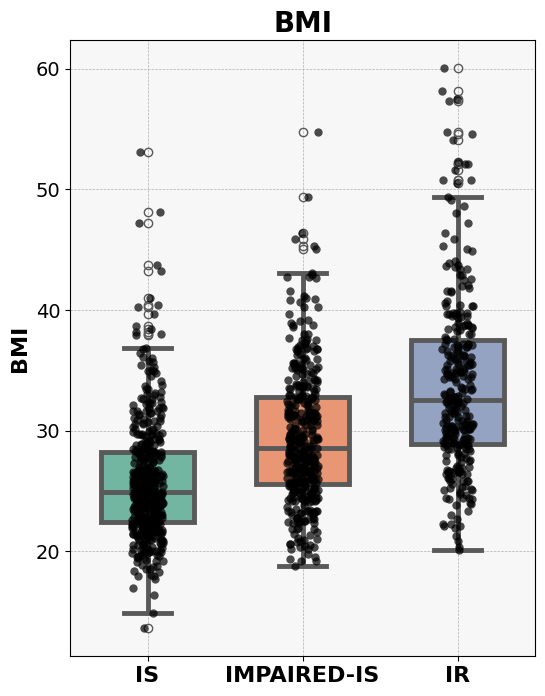

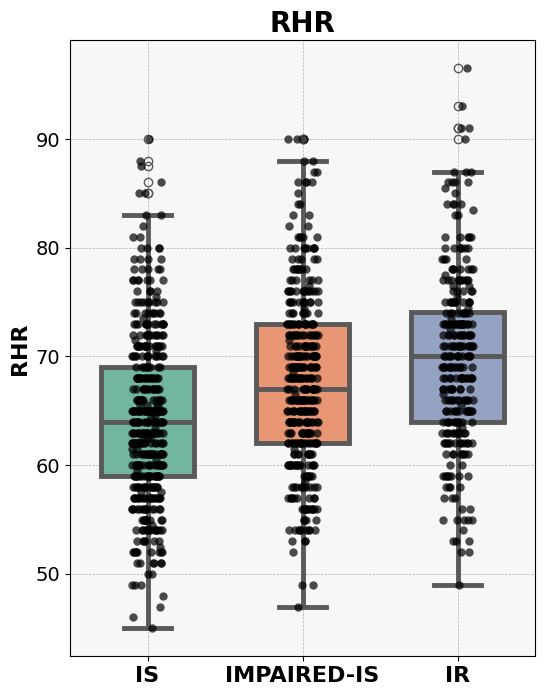

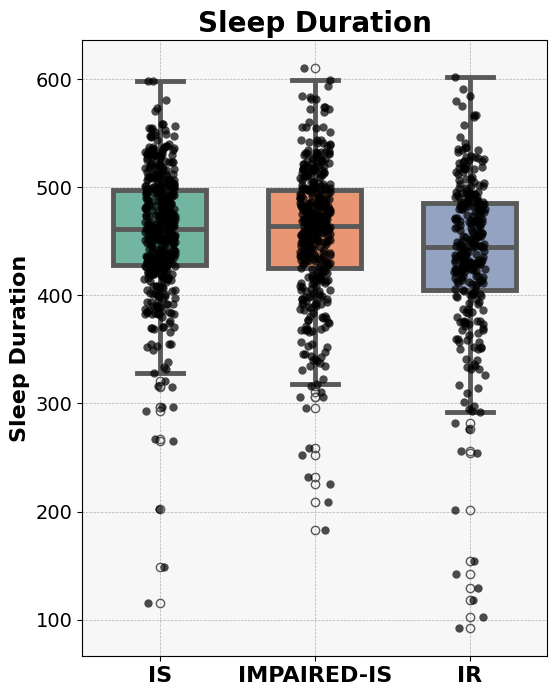

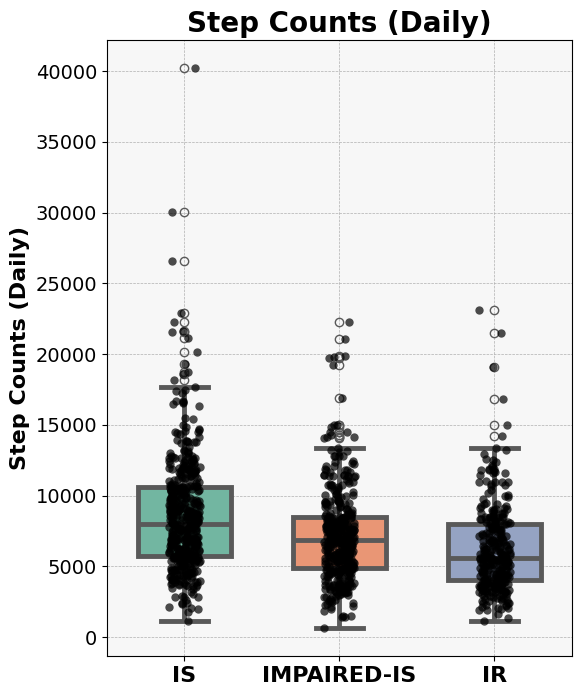

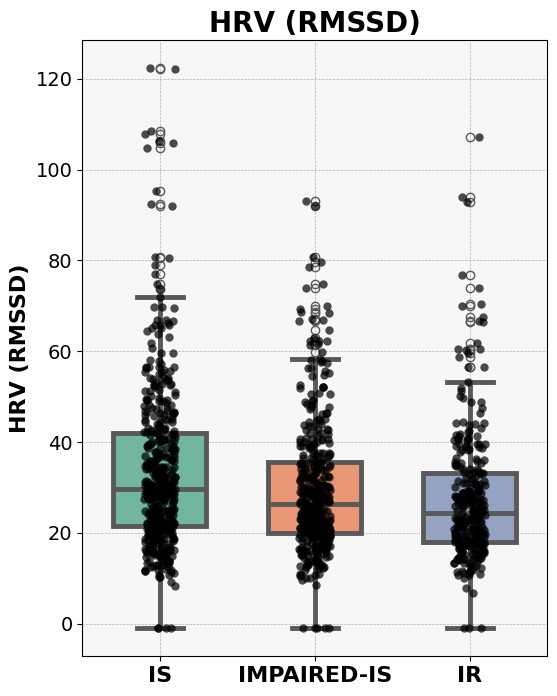

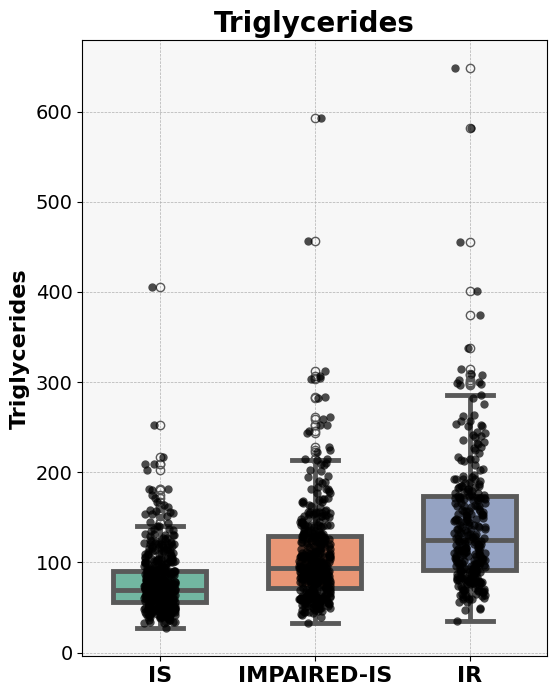

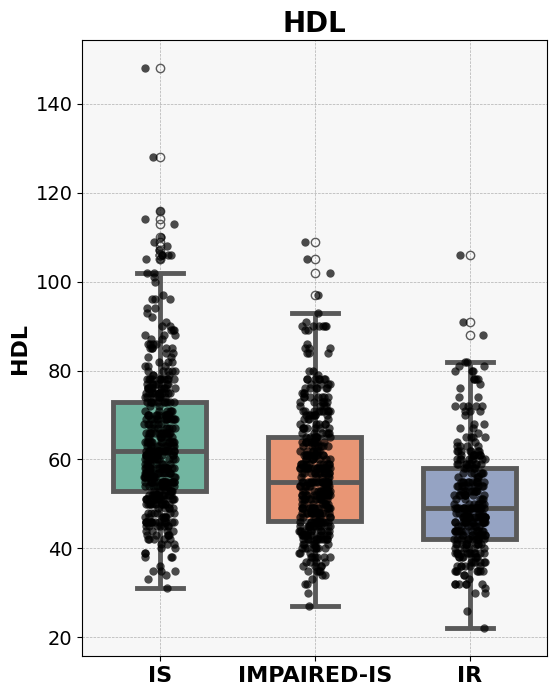

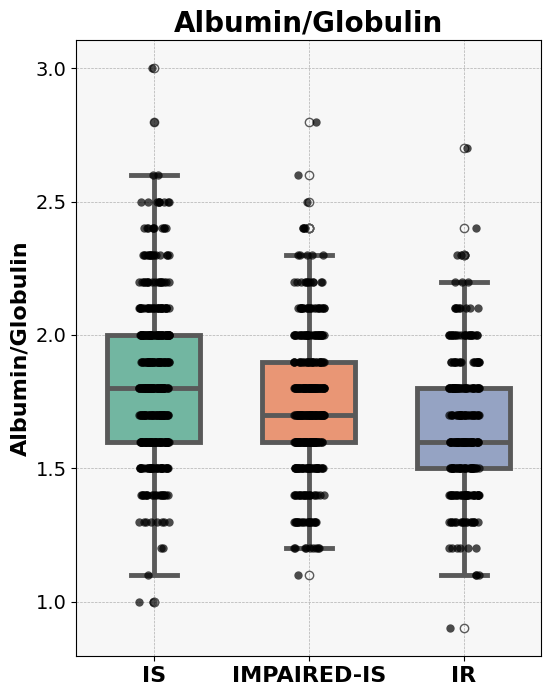

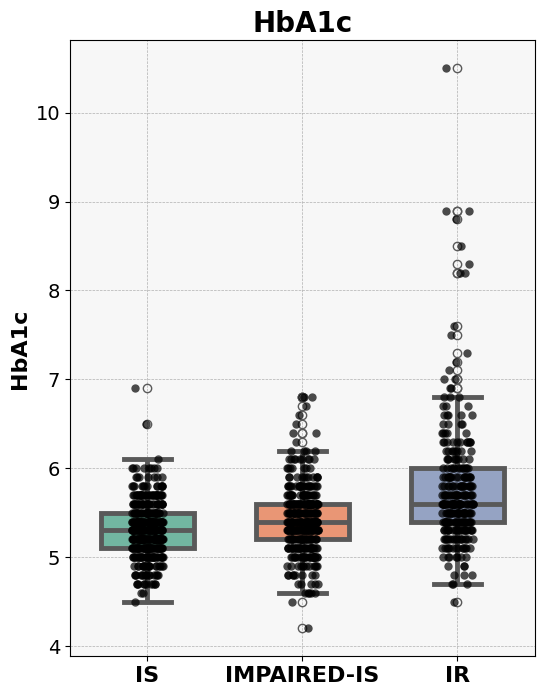

In [ ]:
#@title Create Box plot for Lifestyle and blood biomarkers
def plot_boxplot(filtered_df_for_plotting, y_axis, x_axis, y_axis_label, x_axis_label):
  # Create a figure and axis
  plt.figure(figsize=(6, 8))

  # Create a box plot with a custom color palette
  palette = sns.color_palette("Set2")

  sns.boxplot(x=x_axis, y=y_axis, data=filtered_df_for_plotting, palette=palette, order=["IS", "IMPAIRED-IS", "IR"], width=0.6, linewidth=3.5)

  # Overlay the strip plot (points)
  sns.stripplot(x=x_axis, y=y_axis, data=filtered_df_for_plotting, color='black', order=["IS", "IMPAIRED-IS", "IR"], size=6, jitter=True, alpha=0.7)

  # Customize the title and labels
  plt.title(y_axis_label, fontsize=20, weight='bold')
  plt.xlabel(x_axis_label, fontsize=16, weight='bold')
  plt.ylabel(y_axis_label, fontsize=16, weight='bold')

  # Customize the ticks on x and y axis
  plt.xticks(fontsize=16, weight='bold')
  plt.yticks(fontsize=14)

  # Add gridlines for better readability
  plt.grid(True, which='both', linestyle='--', linewidth=0.5)

  # Add a background color to the plot area
  plt.gca().set_facecolor('#f7f7f7')

  figure_name = y_axis + "_" + x_axis + "01212025_2"
  figure_name = figure_name.replace("/", "_")
  print(f'Saving figures with name: {figure_name}')

  png_figure_file_path = os.path.join(OUTPUTS_FOLDER, f'{figure_name}.png')
  with open(png_figure_file_path, 'wb') as f:
    plt.savefig(f, dpi=300, format="png", bbox_inches="tight")
    print(f'Saved figure to {png_figure_file_path}')

  pdf_figure_file_path = os.path.join(OUTPUTS_FOLDER, f'{figure_name}.pdf')
  with open(pdf_figure_file_path, 'wb') as f:
    plt.savefig(f, dpi=300, format="pdf", bbox_inches="tight")
    print(f'Saved figure to {pdf_figure_file_path}')

  svg_figure_file_path = os.path.join(OUTPUTS_FOLDER, f'{figure_name}.svg')
  with open(svg_figure_file_path, 'wb') as f:
    plt.savefig(f, dpi=300, format="svg", bbox_inches="tight")
    print(f'Saved figure to {svg_figure_file_path}')

  jpeg_figure_file_path = os.path.join(OUTPUTS_FOLDER, f'{figure_name}.jpeg')
  with open(jpeg_figure_file_path, 'wb') as f:
    plt.savefig(f, dpi=300, format="jpeg", bbox_inches="tight")
    print(f'Saved figure to {jpeg_figure_file_path}')

## BMI
test = labels_and_scores_digital_biomarkers_cleaned
plot_boxplot(filtered_df_for_plotting = test, y_axis = "bmi", x_axis = "homa_ir_status", y_axis_label = "BMI", x_axis_label = "")

## rhr
test = labels_and_scores_digital_biomarkers_cleaned
plot_boxplot(filtered_df_for_plotting = test, y_axis = "RHR_FreeLiving_median", x_axis = "homa_ir_status", y_axis_label = "RHR", x_axis_label = "")

## sleep
test = labels_and_scores_digital_biomarkers_cleaned
plot_boxplot(filtered_df_for_plotting = test, y_axis = "SLEEP_Duration_median", x_axis = "homa_ir_status", y_axis_label = "Sleep Duration", x_axis_label = "")

## Steps
test = labels_and_scores_digital_biomarkers_cleaned
plot_boxplot(filtered_df_for_plotting = test, y_axis = "STEPS_Daily_median", x_axis = "homa_ir_status", y_axis_label = "Step Counts (Daily)", x_axis_label = "")

## HRV
test = labels_and_scores_digital_biomarkers_cleaned
plot_boxplot(filtered_df_for_plotting = test, y_axis = "HRV_FreeLiving_median", x_axis = "homa_ir_status", y_axis_label = "HRV (RMSSD)", x_axis_label = "")

## triglycerides
test = labels_and_scores_digital_biomarkers_cleaned
plot_boxplot(filtered_df_for_plotting = test, y_axis = "triglycerides", x_axis = "homa_ir_status", y_axis_label = "Triglycerides", x_axis_label = "")

## hdl
test = labels_and_scores_digital_biomarkers_cleaned
plot_boxplot(filtered_df_for_plotting = test, y_axis = "hdl", x_axis = "homa_ir_status", y_axis_label = "HDL", x_axis_label = "")

## 'albumin/globulin'
test = labels_and_scores_digital_biomarkers_cleaned
plot_boxplot(filtered_df_for_plotting = test, y_axis = "albumin/globulin", x_axis = "homa_ir_status", y_axis_label = "Albumin/Globulin", x_axis_label = "")

## hba1c
test = labels_and_scores_digital_biomarkers_cleaned
plot_boxplot(filtered_df_for_plotting = test, y_axis = "hba1c", x_axis = "homa_ir_status", y_axis_label = "HbA1c", x_axis_label = "")


<Figure size 800x1000 with 0 Axes>

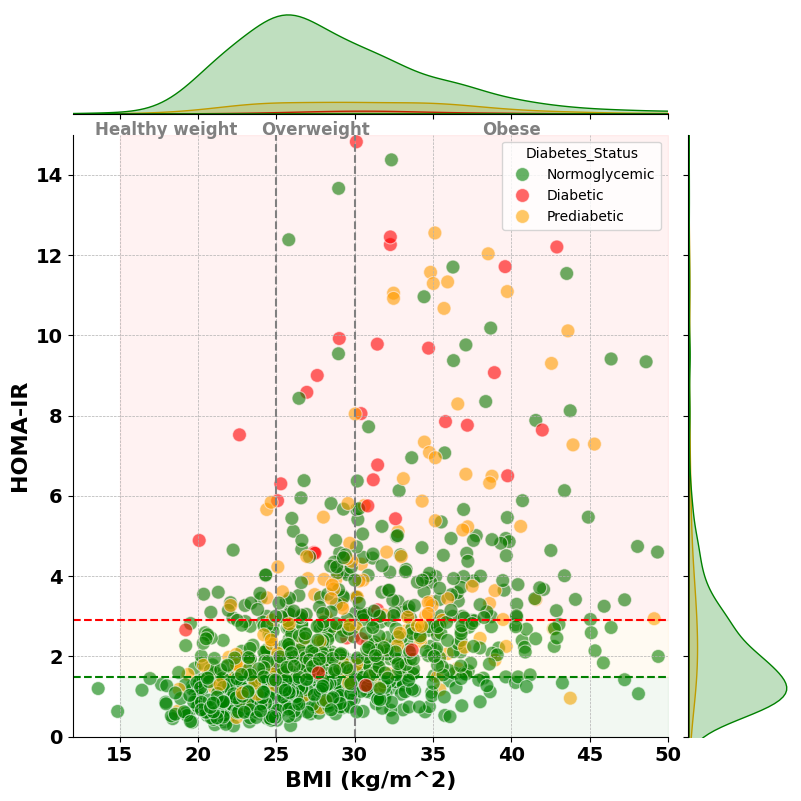

Saving figures with name: homa_ir_bmi_diabetes_status_01212025_2
Saved figure to /content/output_data/homa_ir_bmi_diabetes_status_01212025_2.png
Saved figure to /content/output_data/homa_ir_bmi_diabetes_status_01212025_2.pdf
Saved figure to /content/output_data/homa_ir_bmi_diabetes_status_01212025_2.svg
Saved figure to /content/output_data/homa_ir_bmi_diabetes_status_01212025_2.jpeg


<Figure size 640x480 with 0 Axes>

In [ ]:
#@title Highlight Diabates Status on the scatter plot
# Create a new column named 'Diabetes_Status'
def assign_status(row):
  if row['hba1c'] > 6.5:
    return 'Diabetic'
  elif row['hba1c'] >= 5.7 and row['hba1c'] <= 6.4:
    return 'Prediabetic'
  else:
    return 'Normoglycemic'

labels_and_scores_digital_biomarkers_cleaned['Diabetes_Status'] = labels_and_scores_digital_biomarkers_cleaned.apply(assign_status, axis=1)

# plt.figure(figsize=(8, 10))
plt.figure(figsize=(8, 10))

color_palette = {'Normoglycemic': 'green', 'Prediabetic': 'orange', 'Diabetic': 'red'}
marker_styles = {'Normoglycemic': 'o', 'Prediabetic': 's', 'Diabetic': '^'}
g = sns.jointplot(data=labels_and_scores_digital_biomarkers_cleaned, x="bmi",
              y="homa_ir", hue="Diabetes_Status", palette=color_palette, height=8,
              s=100, alpha = 0.6)

## Shade area between HOMA-IR classes
plt.fill_betweenx(y=[0, 1.5], x1 = 15, x2 = 50, color='green', alpha=0.05, label='Shaded Area')
plt.fill_betweenx(y=[1.5, 2.9], x1 = 15, x2 = 50, color='orange', alpha=0.05, label='Shaded Area')
plt.fill_betweenx(y=[2.9, 15], x1 = 15, x2 = 50, color='red', alpha=0.05, label='Shaded Area')


# Add horizontal lines
plt.axhline(y=1.5, color='green', linestyle='--', label='Line 1')
plt.axhline(y=2.9, color='red', linestyle='--', label='Line 2')

# Add vertical lines
plt.axvline(x=25, color='gray', linestyle='--', label='Line 1')
plt.axvline(x=30, color='gray', linestyle='--', label='Line 2')

# Add text annotations
x_axis_limit = 80

plt.text(18, 15, 'Healthy weight', color='gray', fontsize=12, ha='center',fontweight='bold')
plt.text(27.5, 15, 'Overweight', color='gray', fontsize=12, ha='center',fontweight='bold')
plt.text(40, 15, 'Obese', color='gray', fontsize=12, ha='center',fontweight='bold')



# # Set plot labels and title
plt.xlabel('BMI (kg/m^2)', fontsize=16, fontweight='bold')
plt.ylabel('HOMA-IR', fontsize=16, fontweight='bold')
plt.xticks(fontsize=14, fontweight='bold')
plt.yticks(fontsize=14, fontweight='bold')


plt.xlim(left=12, right=50)
plt.ylim(bottom=0, top=15)


# Access the underlying Axes object
ax = g.ax_joint

# Set grid lines
ax.grid(True, which='both', linestyle='--', linewidth=0.5)

plt.show()


#Save figures
figure_name = "homa_ir_bmi_diabetes_status_" + "01212025_2"
figure_name = figure_name.replace("/", "_")
print(f'Saving figures with name: {figure_name}')

png_figure_file_path = os.path.join(OUTPUTS_FOLDER, f'{figure_name}.png')
with open(png_figure_file_path, 'wb') as f:
  plt.savefig(f, dpi=300, format="png", bbox_inches="tight")
  print(f'Saved figure to {png_figure_file_path}')

pdf_figure_file_path = os.path.join(OUTPUTS_FOLDER, f'{figure_name}.pdf')
with open(pdf_figure_file_path, 'wb') as f:
  plt.savefig(f, dpi=300, format="pdf", bbox_inches="tight")
  print(f'Saved figure to {pdf_figure_file_path}')

svg_figure_file_path = os.path.join(OUTPUTS_FOLDER, f'{figure_name}.svg')
with open(svg_figure_file_path, 'wb') as f:
  plt.savefig(f, dpi=300, format="svg", bbox_inches="tight")
  print(f'Saved figure to {svg_figure_file_path}')

jpeg_figure_file_path = os.path.join(OUTPUTS_FOLDER, f'{figure_name}.jpeg')
with open(jpeg_figure_file_path, 'wb') as f:
  plt.savefig(f, dpi=300, format="jpeg", bbox_inches="tight")
  print(f'Saved figure to {jpeg_figure_file_path}')


In [ ]:
#@title Correlation Figures

## Subset pvalue and correlations
features_of_interest = [
 'bmi',
 'age',
 'hypertension_binary',
 'RHR_FreeLiving_median',
 'RHR_FreeLiving_std',
 'HRV_FreeLiving_median',
 'HRV_FreeLiving_std',
 'STEPS_Daily_median',
 'STEPS_Daily_std',
 'SLEEP_Duration_median',
 'SLEEP_Duration_std',
 'total cholesterol',
 'hdl',
 'triglycerides',
 'ldl',
 'chol/hdl',
 'non hdl',
 'glucose',
 'bun',
 'creatinine',
 'egfr',
 'sodium',
 'potassium',
 'chloride',
 'co2',
 'calcium',
 'total protein',
 'albumin',
 'globulin',
 'albumin/globulin',
 'total bilirubin',
 'alp',
 'ast',
 'alt',
 'hba1c',
 'homa_ir',
 'insulin']

df_clean = labels_and_scores_digital_biomarkers_cleaned[features_of_interest].dropna()

# Get correlation matrix and p-value matrix
correlation_matrix, pvalue_matrix = corr_pval(df_clean)

print("Correlation Matrix:\n", correlation_matrix)
print("\nP-Value Matrix:\n", pvalue_matrix)


correlation_subset = correlation_matrix.loc[features_of_interest, features_of_interest]
pvalue_subset = pvalue_matrix.loc[features_of_interest, features_of_interest]
corr_sorted_row = correlation_subset["homa_ir"].sort_values(ascending=False)
pvalue_sorted_row = pvalue_subset["homa_ir"].sort_values(ascending=False)

index_to_remove = ["homa_ir", "insulin"]  # List of indices to remove

corr_sorted_row = corr_sorted_row.drop(index_to_remove)
pvalue_sorted_row = pvalue_sorted_row.drop(index_to_remove)

corr_pvalue_aggregate = corr_sorted_row.to_frame().merge(pvalue_sorted_row.to_frame(), left_index=True, right_index=True).reset_index(drop=False)

corr_pvalue_aggregate.columns = [['Feature', 'corr_coefficient_w_homa_ir', 'pvalue']]
corr_pvalue_aggregate.columns = corr_pvalue_aggregate.columns.get_level_values(0)
corr_pvalue_aggregate['adjusted_pvalue'] = smm.multipletests(corr_pvalue_aggregate['pvalue'], method='fdr_bh')[1]
corr_pvalue_aggregate


Correlation Matrix:
                             bmi       age  hypertension_binary  \
bmi                    1.000000 -0.047066             0.197521   
age                   -0.047066  1.000000             0.305188   
hypertension_binary    0.197521  0.305188             1.000000   
RHR_FreeLiving_median  0.251492 -0.181355             0.057962   
RHR_FreeLiving_std     0.098747 -0.181974             0.020991   
HRV_FreeLiving_median -0.064841 -0.373684            -0.213497   
HRV_FreeLiving_std    -0.010422 -0.166287            -0.106797   
STEPS_Daily_median    -0.280928  0.018876            -0.088399   
STEPS_Daily_std       -0.219200 -0.075594            -0.152611   
SLEEP_Duration_median -0.119198  0.016216            -0.020091   
SLEEP_Duration_std     0.146407 -0.116190             0.054843   
total cholesterol     -0.048183  0.067332            -0.105110   
hdl                   -0.279957  0.181219            -0.064607   
triglycerides          0.268544  0.041024             0

,Feature,corr_coefficient_w_homa_ir,pvalue,adjusted_pvalue
0,glucose,0.566926,1.112810e-98,3.894834e-97
1,hba1c,0.441148,6.605932e-56,1.156038e-54
2,bmi,0.433588,7.313533e-54,8.532455e-53
3,triglycerides,0.412750,1.725422e-48,1.509744e-47
4,RHR_FreeLiving_median,0.274647,2.483131e-21,1.448493e-20
5,chol/hdl,0.248564,1.221022e-17,5.341973e-17
6,hypertension_binary,0.247408,1.741165e-17,6.771196e-17
7,alt,0.194445,2.981873e-11,9.487779e-11
8,alp,0.193580,3.657670e-11,1.066820e-10
9,globulin,0.184040,3.270849e-10,8.806133e-10


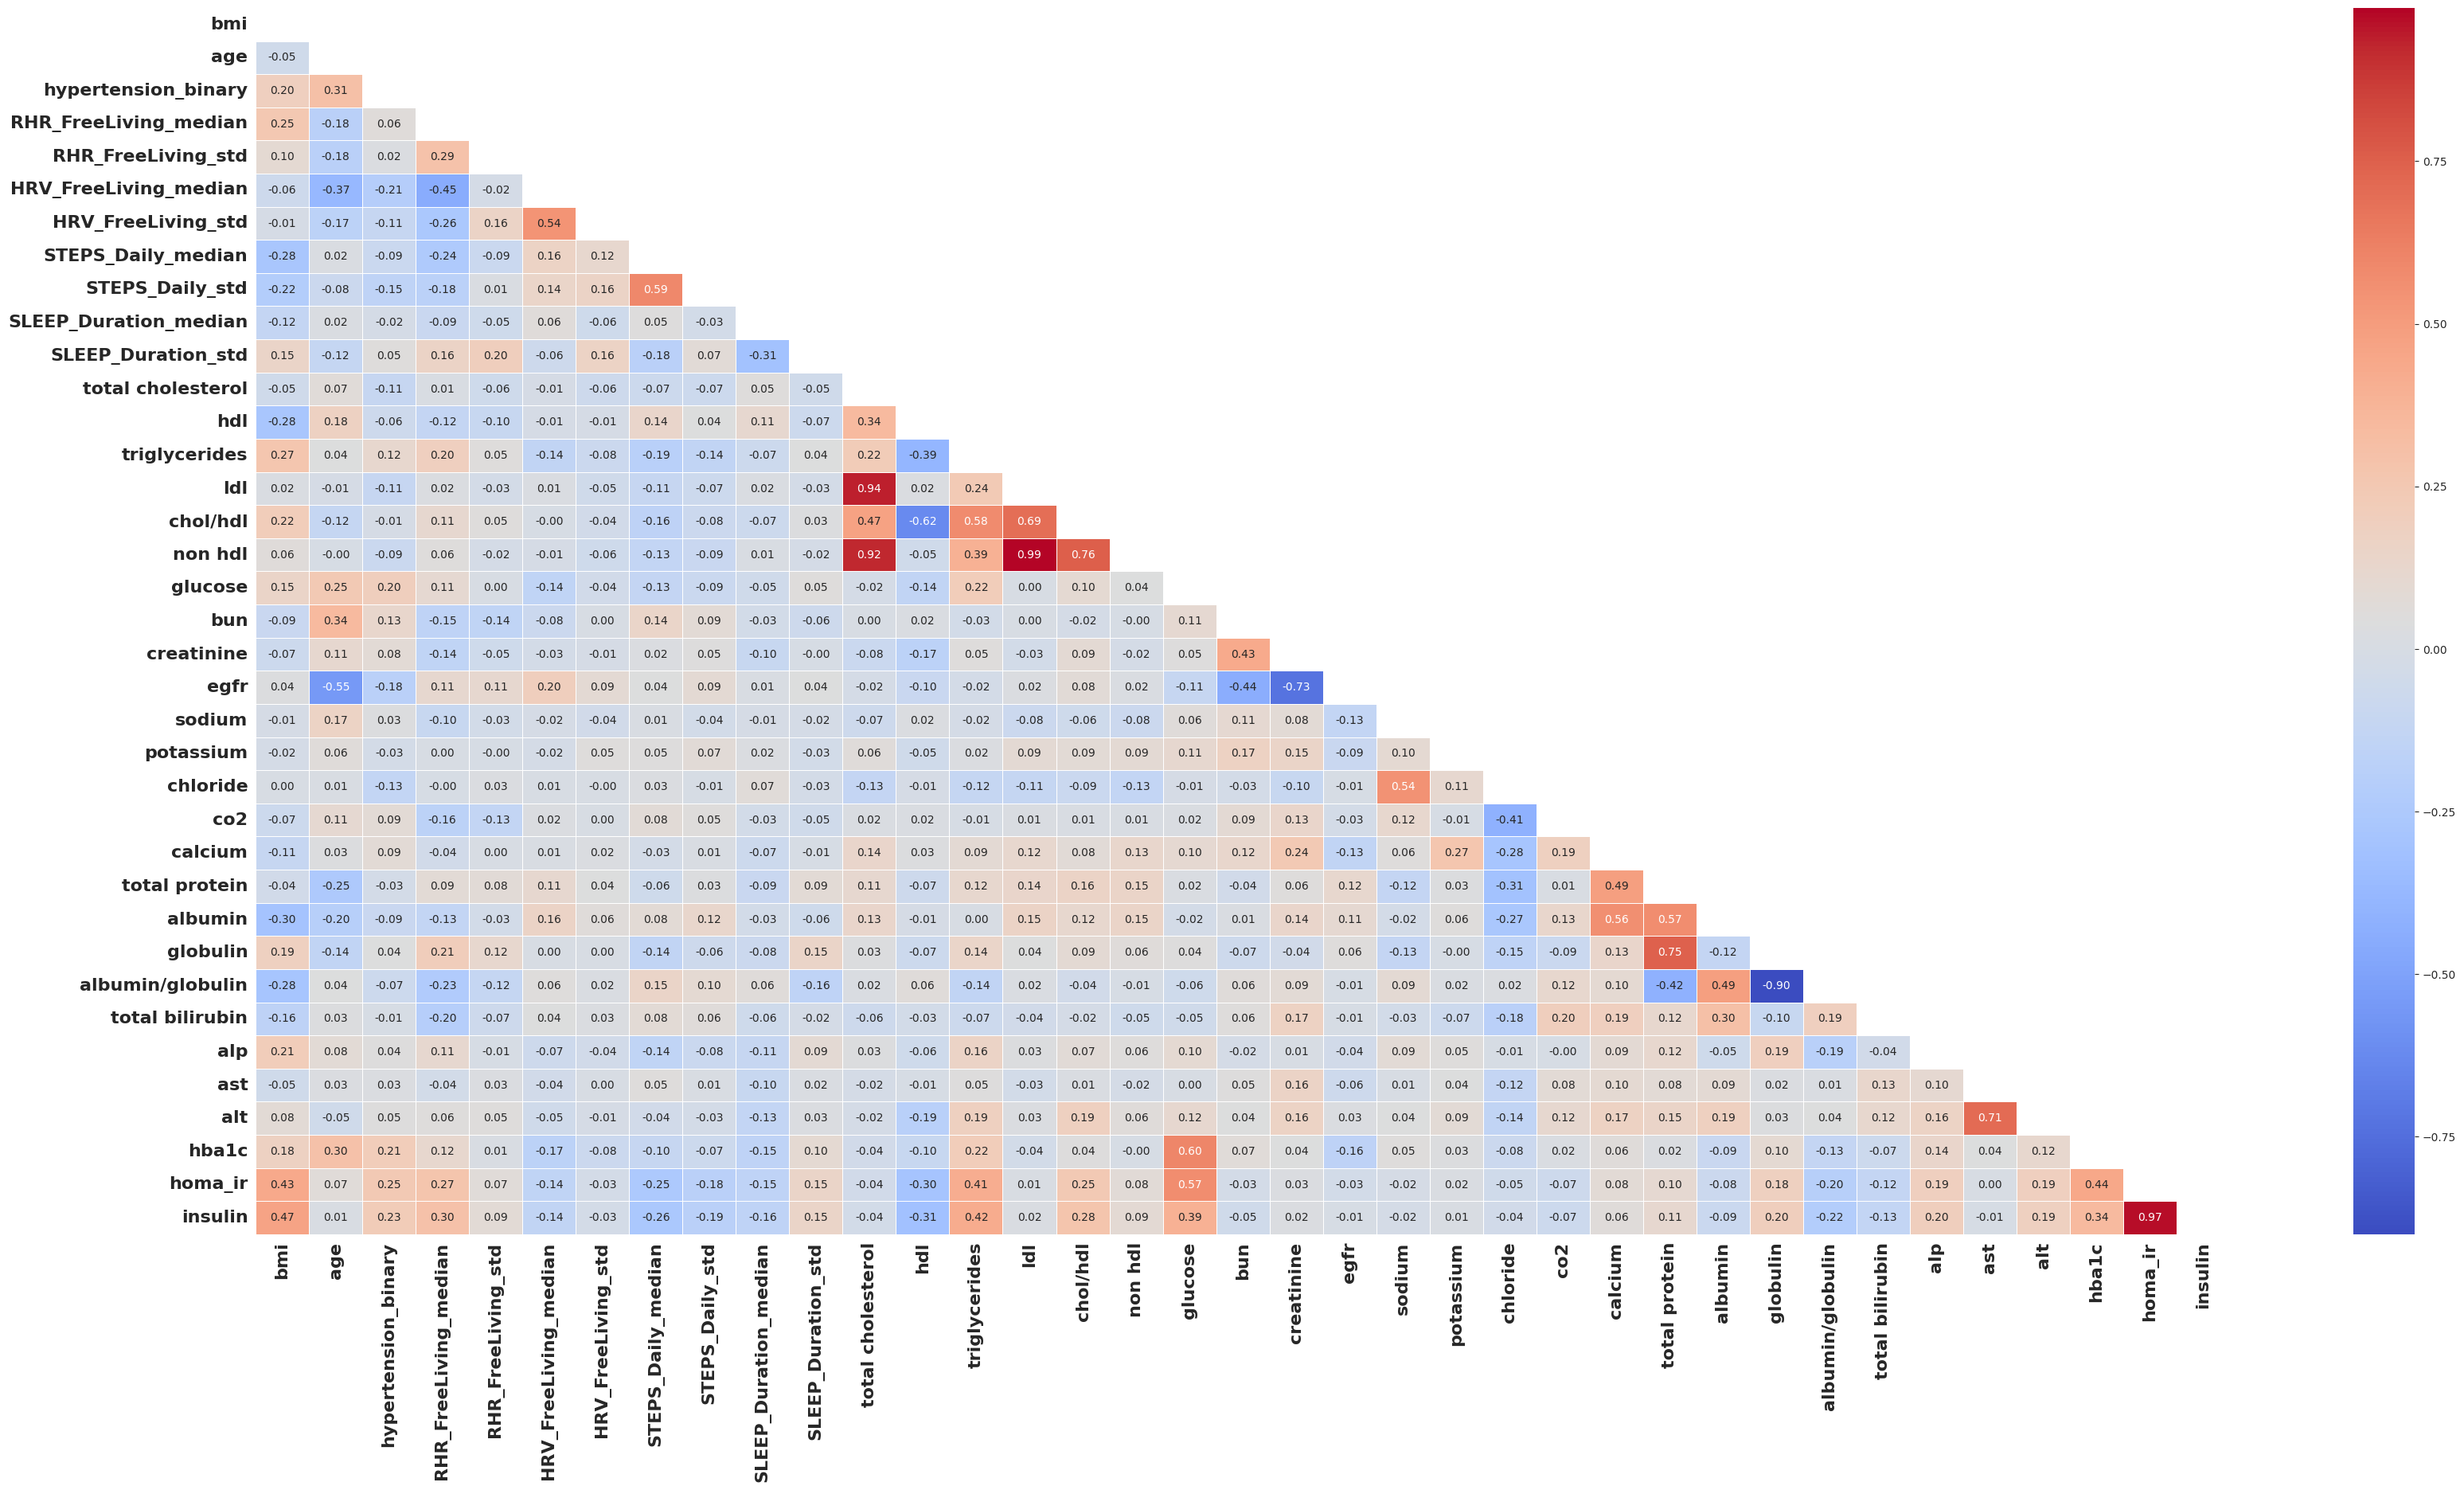

In [ ]:
# Create a heatmap
## Optimize Correlation Matrix

features_of_interest = ['bmi',
 'age',
 'hypertension_binary',
 'RHR_FreeLiving_median',
 'RHR_FreeLiving_std',
 'HRV_FreeLiving_median',
 'HRV_FreeLiving_std',
 'STEPS_Daily_median',
 'STEPS_Daily_std',
 'SLEEP_Duration_median',
 'SLEEP_Duration_std',
 'total cholesterol',
 'hdl',
 'triglycerides',
 'ldl',
 'chol/hdl',
 'non hdl',
 'glucose',
 'bun',
 'creatinine',
 'egfr',
 'sodium',
 'potassium',
 'chloride',
 'co2',
 'calcium',
 'total protein',
 'albumin',
 'globulin',
 'albumin/globulin',
 'total bilirubin',
 'alp',
 'ast',
 'alt',
 'hba1c',
 'homa_ir',
 'insulin']
correlation_subset = correlation_matrix.loc[features_of_interest, features_of_interest]

sns.set_style(style='white')
# Create a mask for the upper triangle
mask = np.triu(np.ones_like(correlation_subset))
# Create a heatmap using Seaborn
plt.figure(figsize=(40, 20))

# heatmap = sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5, mask=mask)
heatmap = sns.heatmap(correlation_subset, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5, mask=mask)

# # Increase font size of x-axis and y-axis labels
heatmap.set_xticklabels(heatmap.get_xticklabels(), fontsize=16)
heatmap.set_yticklabels(heatmap.get_yticklabels(), fontsize=16)


plt.xticks(fontweight='bold')
plt.yticks(fontweight='bold')

# Show the plot
plt.show()

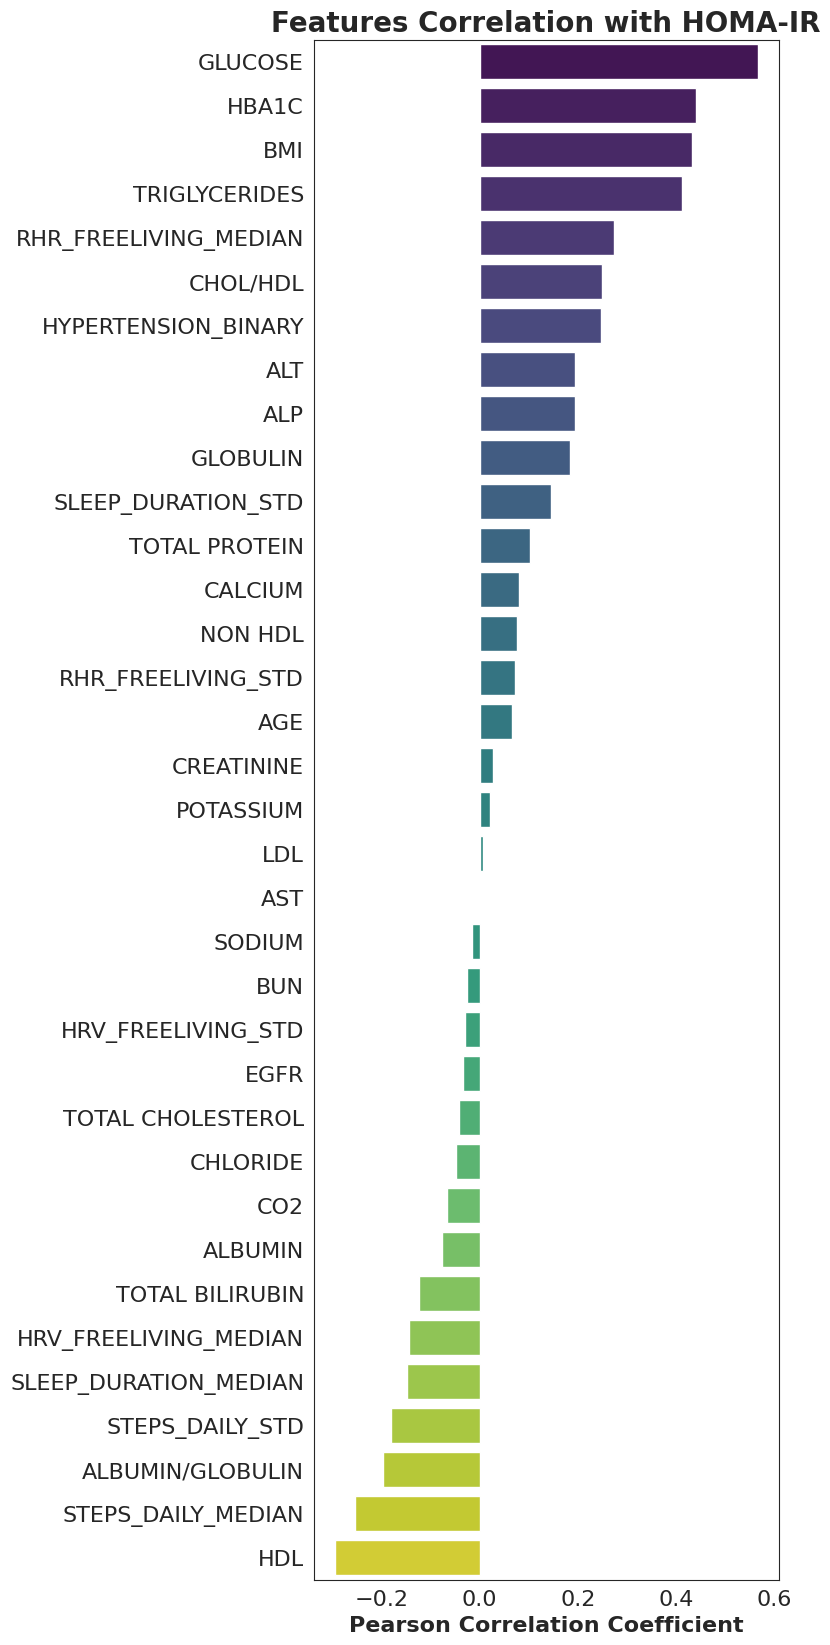

In [ ]:
# Sort DataFrame by 'Value' column (descending order)
sorted_row = correlation_subset["homa_ir"].sort_values(ascending=False)

index_to_remove = ["homa_ir", "insulin"]  # List of indices to remove
sorted_row = sorted_row.drop(index_to_remove)

# modified_indexes = [index.lower().capitalize() for index in sorted_row.index]
modified_indexes = [index.upper() for index in sorted_row.index]
sorted_row.index = modified_indexes

# Plotting
plt.figure(figsize=(6, 20))  # Adjust the figure size as needed
sns.barplot(x=sorted_row.values, y=sorted_row.index, palette="viridis")

# Adding labels and title
plt.title('Features Correlation with HOMA-IR', fontsize=20, weight='bold')
plt.xlabel('Pearson Correlation Coefficient', fontsize=16, weight='bold')
plt.ylabel('', fontsize=16, weight='bold')



# Customize the ticks on x and y axis
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)


plt.show()

In [ ]:
corr_pvalue_aggregate['pvalue'].apply(lambda x: "{:.2e}".format(x))

,pvalue
0,1.11e-98
1,6.61e-56
2,7.31e-54
3,1.73e-48
4,2.48e-21
5,1.22e-17
6,1.74e-17
7,2.98e-11
8,3.66e-11
9,3.27e-10


In [ ]:
print("Columns in the correlation subset:")
print(correlation_subset.columns)

Columns in the correlation subset:
Index(['bmi', 'age', 'hypertension_binary', 'RHR_FreeLiving_median',
       'RHR_FreeLiving_std', 'HRV_FreeLiving_median', 'HRV_FreeLiving_std',
       'STEPS_Daily_median', 'STEPS_Daily_std', 'SLEEP_Duration_median',
       'SLEEP_Duration_std', 'total cholesterol', 'hdl', 'triglycerides',
       'ldl', 'chol/hdl', 'non hdl', 'glucose', 'bun', 'creatinine', 'egfr',
       'sodium', 'potassium', 'chloride', 'co2', 'calcium', 'total protein',
       'albumin', 'globulin', 'albumin/globulin', 'total bilirubin', 'alp',
       'ast', 'alt', 'hba1c', 'homa_ir', 'insulin'],
      dtype='object')


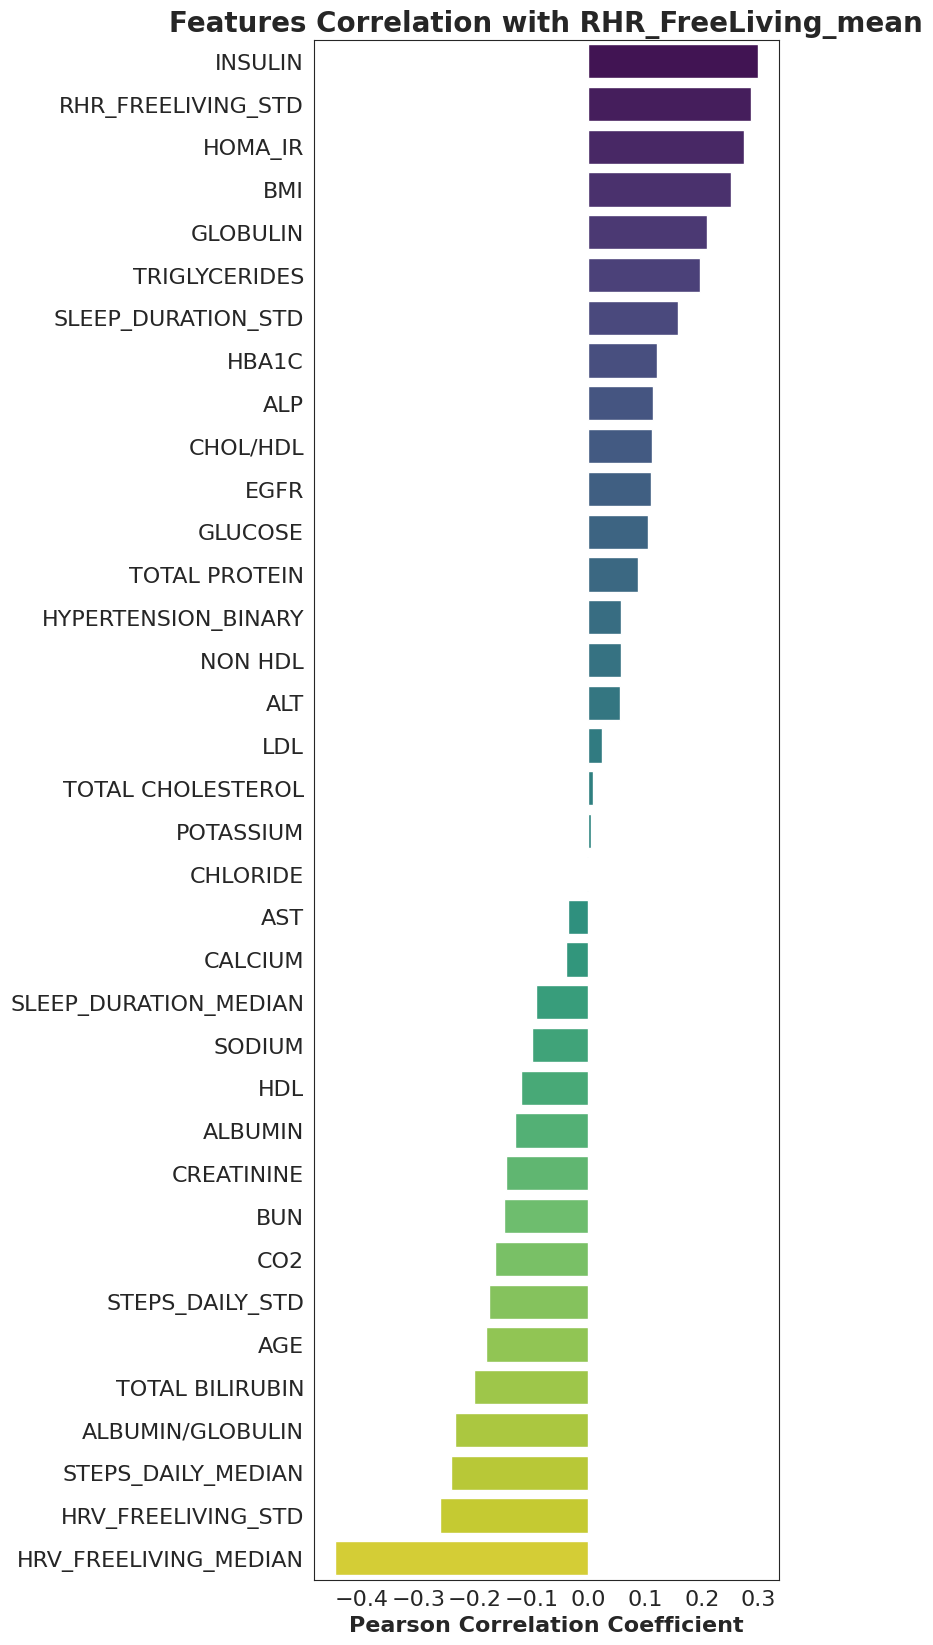

In [ ]:
sorted_row = correlation_subset["RHR_FreeLiving_median"].sort_values(ascending=False)

index_to_remove = ["RHR_FreeLiving_median"]  # List of indices to remove
sorted_row = sorted_row.drop(index_to_remove)

modified_indexes = [index.upper() for index in sorted_row.index]
sorted_row.index = modified_indexes

# Plotting
plt.figure(figsize=(6, 20))  # Adjust the figure size as needed
sns.barplot(x=sorted_row.values, y=sorted_row.index, palette="viridis")

# Adding labels and title
plt.title('Features Correlation with RHR_FreeLiving_mean', fontsize=20, weight='bold')
plt.xlabel('Pearson Correlation Coefficient', fontsize=16, weight='bold')
plt.ylabel('', fontsize=16, weight='bold')



# Customize the ticks on x and y axis
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)


plt.show()

In [ ]:
#@title select subset for Supplementary Table
corr_pvalue_aggregate["Feature"] = corr_pvalue_aggregate["Feature"].str.upper()
corr_pvalue_aggregate["corr_coefficient_w_homa_ir"] = corr_pvalue_aggregate["corr_coefficient_w_homa_ir"].round(2)
corr_pvalue_aggregate['pvalue'] = corr_pvalue_aggregate['pvalue'].apply(lambda x: "{:.2e}".format(x))
corr_pvalue_aggregate['adjusted_pvalue'] = corr_pvalue_aggregate['adjusted_pvalue'].apply(lambda x: "{:.2e}".format(x))

corr_pvalue_aggregate

,Feature,corr_coefficient_w_homa_ir,pvalue,adjusted_pvalue
0,GLUCOSE,0.57,1.11e-98,3.89e-97
1,HBA1C,0.44,6.61e-56,1.16e-54
2,BMI,0.43,7.31e-54,8.53e-53
3,TRIGLYCERIDES,0.41,1.73e-48,1.51e-47
4,RHR_FREELIVING_MEDIAN,0.27,2.48e-21,1.45e-20
5,CHOL/HDL,0.25,1.22e-17,5.34e-17
6,HYPERTENSION_BINARY,0.25,1.74e-17,6.77e-17
7,ALT,0.19,2.98e-11,9.49e-11
8,ALP,0.19,3.66e-11,1.07e-10
9,GLOBULIN,0.18,3.27e-10,8.81e-10


### Startify subjects based on Physical activity and BMI

In [ ]:
# @title Upload `experiment_id_to_full_prediction_df_mapping` file from your filesystem.
uploaded = files.upload(target_dir=INPUTS_FOLDER)

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes to folder {folder}'.format(
      name=fn, length=len(uploaded[fn]), folder=INPUTS_FOLDER))

if len(uploaded) == 1:
  EXP_DATA_SOURCE_PATH = fn
  print('Using file: ', EXP_DATA_SOURCE_PATH)
else:
  print('Only one file supported, try again.')

Saving experiment_id_to_full_prediction_df_mapping.pkl to /content/input_data/experiment_id_to_full_prediction_df_mapping (2).pkl
User uploaded file "/content/input_data/experiment_id_to_full_prediction_df_mapping (2).pkl" with length 817859 bytes to folder /content/input_data
Using file:  /content/input_data/experiment_id_to_full_prediction_df_mapping (2).pkl


In [ ]:
#@title Load experiment to dataframe mapping
with open(EXP_DATA_SOURCE_PATH, 'rb') as f:
    dfs = pickle.load(f)

In [ ]:
#@title Assign a group based on BMI and PA

# Define category for HOMA-IR
def categorize_homa_ir(homa_ir):
    if homa_ir > 2.9:
        return 1 #'IR'
    elif homa_ir <= 2.9:
        return 0 #'Non-IR'
    else:
        return 'Unknown'

# Define a function to categorize BMI
def categorize_bmi(bmi):
    if bmi < 18.5:
        return 'Underweight'
    elif 18.5 <= bmi < 24.9:
        return 'Normal weight'
    elif 25 <= bmi < 29.9:
        return 'Overweight'
    else:
        return 'Obesity'


# Define a function to categorize physical activity based on step count
def categorize_activity(steps):
    if steps < 5000:
        return 'Sedentary'
    elif 5000 <= steps < 7500:
        return 'Low active'
    elif 7500 <= steps < 10000:
        return 'Somewhat active'
    elif 10000 <= steps < 12500:
        return 'Active'
    else:
        return 'Highly active'


# Define a function to categorize physical activity based on weekly AZM
def categorize_azm(azm):
    if azm < 150:
        return 'Sedentary'
    elif 150 <= azm < 300:
        return 'Low active'
    elif 300 <= azm < 450:
        return 'Active'
    else:
        return 'Highly active'



def categorize_diabetes(hb1c):
  if hb1c > 6.5:
    return 'Diabetic'
  elif hb1c >= 5.7 and hb1c <= 6.4:
    return 'Prediabetic'
  else:
    return 'Normoglycemic'

In [ ]:
#@title Calculate performance per class
def calculate_performance(df, subgroup = "Test"):
  # Calculate confusion matrix
  tn, fp, fn, tp = confusion_matrix(df['homa_ir_class_true'],
                        df['homa_ir_class_predicted'] ).ravel()

  # Calculate sensitivity and specificity
  sensitivity = round(tp / (tp + fn),3)
  specificity = round(tn / (tn + fp),3)


  ## Calculate adjusted specificty
  impaired_predicted_as_ir = df[(df["true_values"]<=2.9) & (df["true_values"]>=1.5) & (df["predicted_values"]>2.9)]
  num_impaired_predicted_as_ir = impaired_predicted_as_ir.shape[0]
  fp_adjusted = fp - num_impaired_predicted_as_ir
  adjusted_specificity = round(tn / (tn + fp_adjusted),3)

  print(f"subgroup: {subgroup}", f"Sensitivity: {sensitivity}", f"Specificity: {specificity}", f"AdjustedSpecificity: {adjusted_specificity}", f"tn: {tn}", f"fp: {fp}", f"fp_adjusted: {fp_adjusted}")
  print("Dimension = ", df.shape)
  display(df[(df["true_values"]<1.5) & (df["predicted_values"]>2.9)])

  columns = ['Subgroup', 'Sensitivity', 'Specificity', 'AdjustedSpecificity']
  perf_df = pd.DataFrame([[subgroup, round(sensitivity,2), round(specificity,2), round(adjusted_specificity,2)]], columns=columns)

  return perf_df


(1173, 4)
(1165, 159)
subgroup: All cohort Sensitivity: 0.76 Specificity: 0.84 AdjustedSpecificity: 0.971 tn: 727 fp: 138 fp_adjusted: 22
Dimension =  (1165, 164)


,participant_id,predicted_values,true_values,Experiment_ID,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,...,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary,Diabetes_Status,homa_ir_class_true,homa_ir_class_predicted,bmi_class,physical_activity_class_steps,diabetes_class
131,13699,3.346045,1.22,EXP_11,77.881720,77.0,3.277604,19.084679,18.7695,6.289622,...,None,NaN,0.094271,0,Normoglycemic,0,1,Obesity,Sedentary,Normoglycemic
152,13819,2.921984,0.72,EXP_11,57.797980,58.0,2.146795,16.404041,16.1420,4.429918,...,None,NaN,0.242692,1,Normoglycemic,0,1,Overweight,Low active,Normoglycemic
191,55870,2.952543,0.66,EXP_11,71.257143,71.0,4.159565,62.205130,63.7720,15.867430,...,None,NaN,0.158290,0,Normoglycemic,0,1,Obesity,Low active,Normoglycemic
328,56418,3.009351,0.77,EXP_11,61.970297,62.0,2.192050,29.781350,30.0265,6.525426,...,None,NaN,0.204082,1,Normoglycemic,0,1,Obesity,Low active,Normoglycemic
377,56883,3.488820,1.18,EXP_11,71.947368,72.0,6.800652,46.354786,36.1585,47.186600,...,None,NaN,0.502092,0,Normoglycemic,0,1,Normal weight,Low active,Normoglycemic
384,56921,3.275285,1.35,EXP_11,71.563636,72.0,2.168800,17.900327,18.0995,3.762211,...,None,NaN,0.267417,1,Normoglycemic,0,1,Obesity,Low active,Normoglycemic
494,57609,3.029352,1.46,EXP_11,63.689320,64.0,1.848027,80.528835,80.7250,10.486620,...,None,NaN,0.128968,0,Normoglycemic,0,1,Normal weight,Somewhat active,Normoglycemic
497,57628,3.020782,1.17,EXP_11,64.427350,65.0,2.601803,54.463519,52.7555,14.056547,...,None,NaN,0.091185,0,Prediabetic,0,1,Obesity,Low active,Prediabetic
510,57672,3.234647,1.13,EXP_11,61.552381,62.0,2.573256,46.233162,49.0370,14.473240,...,None,NaN,0.209314,0,Normoglycemic,0,1,Overweight,Somewhat active,Normoglycemic
536,57853,3.461545,1.34,EXP_11,75.474747,75.0,4.244658,34.240717,34.9030,10.327120,...,None,NaN,0.239144,0,Normoglycemic,0,1,Obesity,Low active,Normoglycemic


subgroup: Obesity Sensitivity: 0.863 Specificity: 0.676 AdjustedSpecificity: 0.934 tn: 171 fp: 82 fp_adjusted: 12
Dimension =  (458, 164)


,participant_id,predicted_values,true_values,Experiment_ID,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,...,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary,Diabetes_Status,homa_ir_class_true,homa_ir_class_predicted,bmi_class,physical_activity_class_steps,diabetes_class
131,13699,3.346045,1.22,EXP_11,77.881720,77.0,3.277604,19.084679,18.7695,6.289622,...,None,NaN,0.094271,0,Normoglycemic,0,1,Obesity,Sedentary,Normoglycemic
191,55870,2.952543,0.66,EXP_11,71.257143,71.0,4.159565,62.205130,63.7720,15.867430,...,None,NaN,0.158290,0,Normoglycemic,0,1,Obesity,Low active,Normoglycemic
328,56418,3.009351,0.77,EXP_11,61.970297,62.0,2.192050,29.781350,30.0265,6.525426,...,None,NaN,0.204082,1,Normoglycemic,0,1,Obesity,Low active,Normoglycemic
384,56921,3.275285,1.35,EXP_11,71.563636,72.0,2.168800,17.900327,18.0995,3.762211,...,None,NaN,0.267417,1,Normoglycemic,0,1,Obesity,Low active,Normoglycemic
497,57628,3.020782,1.17,EXP_11,64.427350,65.0,2.601803,54.463519,52.7555,14.056547,...,None,NaN,0.091185,0,Prediabetic,0,1,Obesity,Low active,Prediabetic
536,57853,3.461545,1.34,EXP_11,75.474747,75.0,4.244658,34.240717,34.9030,10.327120,...,None,NaN,0.239144,0,Normoglycemic,0,1,Obesity,Low active,Normoglycemic
678,70355,3.664602,1.23,EXP_11,52.941606,52.0,3.448770,34.864829,34.6030,7.471314,...,None,NaN,0.714286,1,Normoglycemic,0,1,Obesity,Somewhat active,Normoglycemic
951,72151,6.946205,1.07,EXP_11,79.828571,79.0,3.869788,23.468922,27.0155,11.959427,...,None,NaN,0.551378,0,Normoglycemic,0,1,Obesity,Somewhat active,Normoglycemic
1057,72772,3.709178,1.42,EXP_11,77.415842,77.0,2.563686,19.213984,18.5970,4.285859,...,None,NaN,0.147917,0,Normoglycemic,0,1,Obesity,Low active,Normoglycemic
1063,72816,2.950277,1.22,EXP_11,68.165217,68.0,1.596560,29.555606,28.7260,9.637907,...,None,NaN,0.185387,0,Normoglycemic,0,1,Obesity,Somewhat active,Normoglycemic


subgroup: Overweight Sensitivity: 0.63 Specificity: 0.875 AdjustedSpecificity: 0.978 tn: 267 fp: 38 fp_adjusted: 6
Dimension =  (378, 164)


...

,participant_id,predicted_values,true_values,Experiment_ID,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,...,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary,Diabetes_Status,homa_ir_class_true,homa_ir_class_predicted,bmi_class,physical_activity_class_steps,diabetes_class
497,57628,3.020782,1.17,EXP_11,64.427350,65.0,2.601803,54.463519,52.7555,14.056547,...,None,NaN,0.091185,0,Prediabetic,0,1,Obesity,Low active,Prediabetic
666,70323,3.366820,1.21,EXP_11,59.652174,59.0,2.702234,36.528487,36.7570,6.097105,...,None,NaN,0.156318,1,Prediabetic,0,1,Normal weight,Sedentary,Prediabetic


subgroup: Normoglycemic Sensitivity: 0.714 Specificity: 0.861 AdjustedSpecificity: 0.972 tn: 668 fp: 108 fp_adjusted: 19
Dimension =  (972, 164)


,participant_id,predicted_values,true_values,Experiment_ID,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,...,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary,Diabetes_Status,homa_ir_class_true,homa_ir_class_predicted,bmi_class,physical_activity_class_steps,diabetes_class
131,13699,3.346045,1.22,EXP_11,77.881720,77.0,3.277604,19.084679,18.7695,6.289622,...,None,NaN,0.094271,0,Normoglycemic,0,1,Obesity,Sedentary,Normoglycemic
152,13819,2.921984,0.72,EXP_11,57.797980,58.0,2.146795,16.404041,16.1420,4.429918,...,None,NaN,0.242692,1,Normoglycemic,0,1,Overweight,Low active,Normoglycemic
191,55870,2.952543,0.66,EXP_11,71.257143,71.0,4.159565,62.205130,63.7720,15.867430,...,None,NaN,0.158290,0,Normoglycemic,0,1,Obesity,Low active,Normoglycemic
328,56418,3.009351,0.77,EXP_11,61.970297,62.0,2.192050,29.781350,30.0265,6.525426,...,None,NaN,0.204082,1,Normoglycemic,0,1,Obesity,Low active,Normoglycemic
377,56883,3.488820,1.18,EXP_11,71.947368,72.0,6.800652,46.354786,36.1585,47.186600,...,None,NaN,0.502092,0,Normoglycemic,0,1,Normal weight,Low active,Normoglycemic
384,56921,3.275285,1.35,EXP_11,71.563636,72.0,2.168800,17.900327,18.0995,3.762211,...,None,NaN,0.267417,1,Normoglycemic,0,1,Obesity,Low active,Normoglycemic
494,57609,3.029352,1.46,EXP_11,63.689320,64.0,1.848027,80.528835,80.7250,10.486620,...,None,NaN,0.128968,0,Normoglycemic,0,1,Normal weight,Somewhat active,Normoglycemic
510,57672,3.234647,1.13,EXP_11,61.552381,62.0,2.573256,46.233162,49.0370,14.473240,...,None,NaN,0.209314,0,Normoglycemic,0,1,Overweight,Somewhat active,Normoglycemic
536,57853,3.461545,1.34,EXP_11,75.474747,75.0,4.244658,34.240717,34.9030,10.327120,...,None,NaN,0.239144,0,Normoglycemic,0,1,Obesity,Low active,Normoglycemic
657,70306,3.980558,1.19,EXP_11,66.294118,66.0,2.788393,29.771059,30.0390,10.385523,...,None,NaN,0.510204,1,Normoglycemic,0,1,Normal weight,Low active,Normoglycemic


,Subgroup,Sensitivity,Specificity,AdjustedSpecificity
0,All cohort,0.76,0.84,0.97
1,Obesity,0.86,0.68,0.93
2,Overweight,0.63,0.88,0.98
3,Normal weight,0.23,0.94,0.99
4,Sedentary,0.88,0.70,0.97
5,Low active,0.76,0.83,0.96
6,Somewhat active,0.64,0.85,0.96
7,Active,0.59,0.90,0.99
8,Highly active,0.58,0.97,1.00
9,Sedentary & Obesity,0.93,0.58,0.95


,Subgroup,Metric,Score
0,All cohort,Sensitivity,0.76
1,Obesity,Sensitivity,0.86
2,Overweight,Sensitivity,0.63
3,Normal weight,Sensitivity,0.23
4,Sedentary,Sensitivity,0.88
5,Low active,Sensitivity,0.76
6,Somewhat active,Sensitivity,0.64
7,Active,Sensitivity,0.59
8,Highly active,Sensitivity,0.58
9,Sedentary & Obesity,Sensitivity,0.93


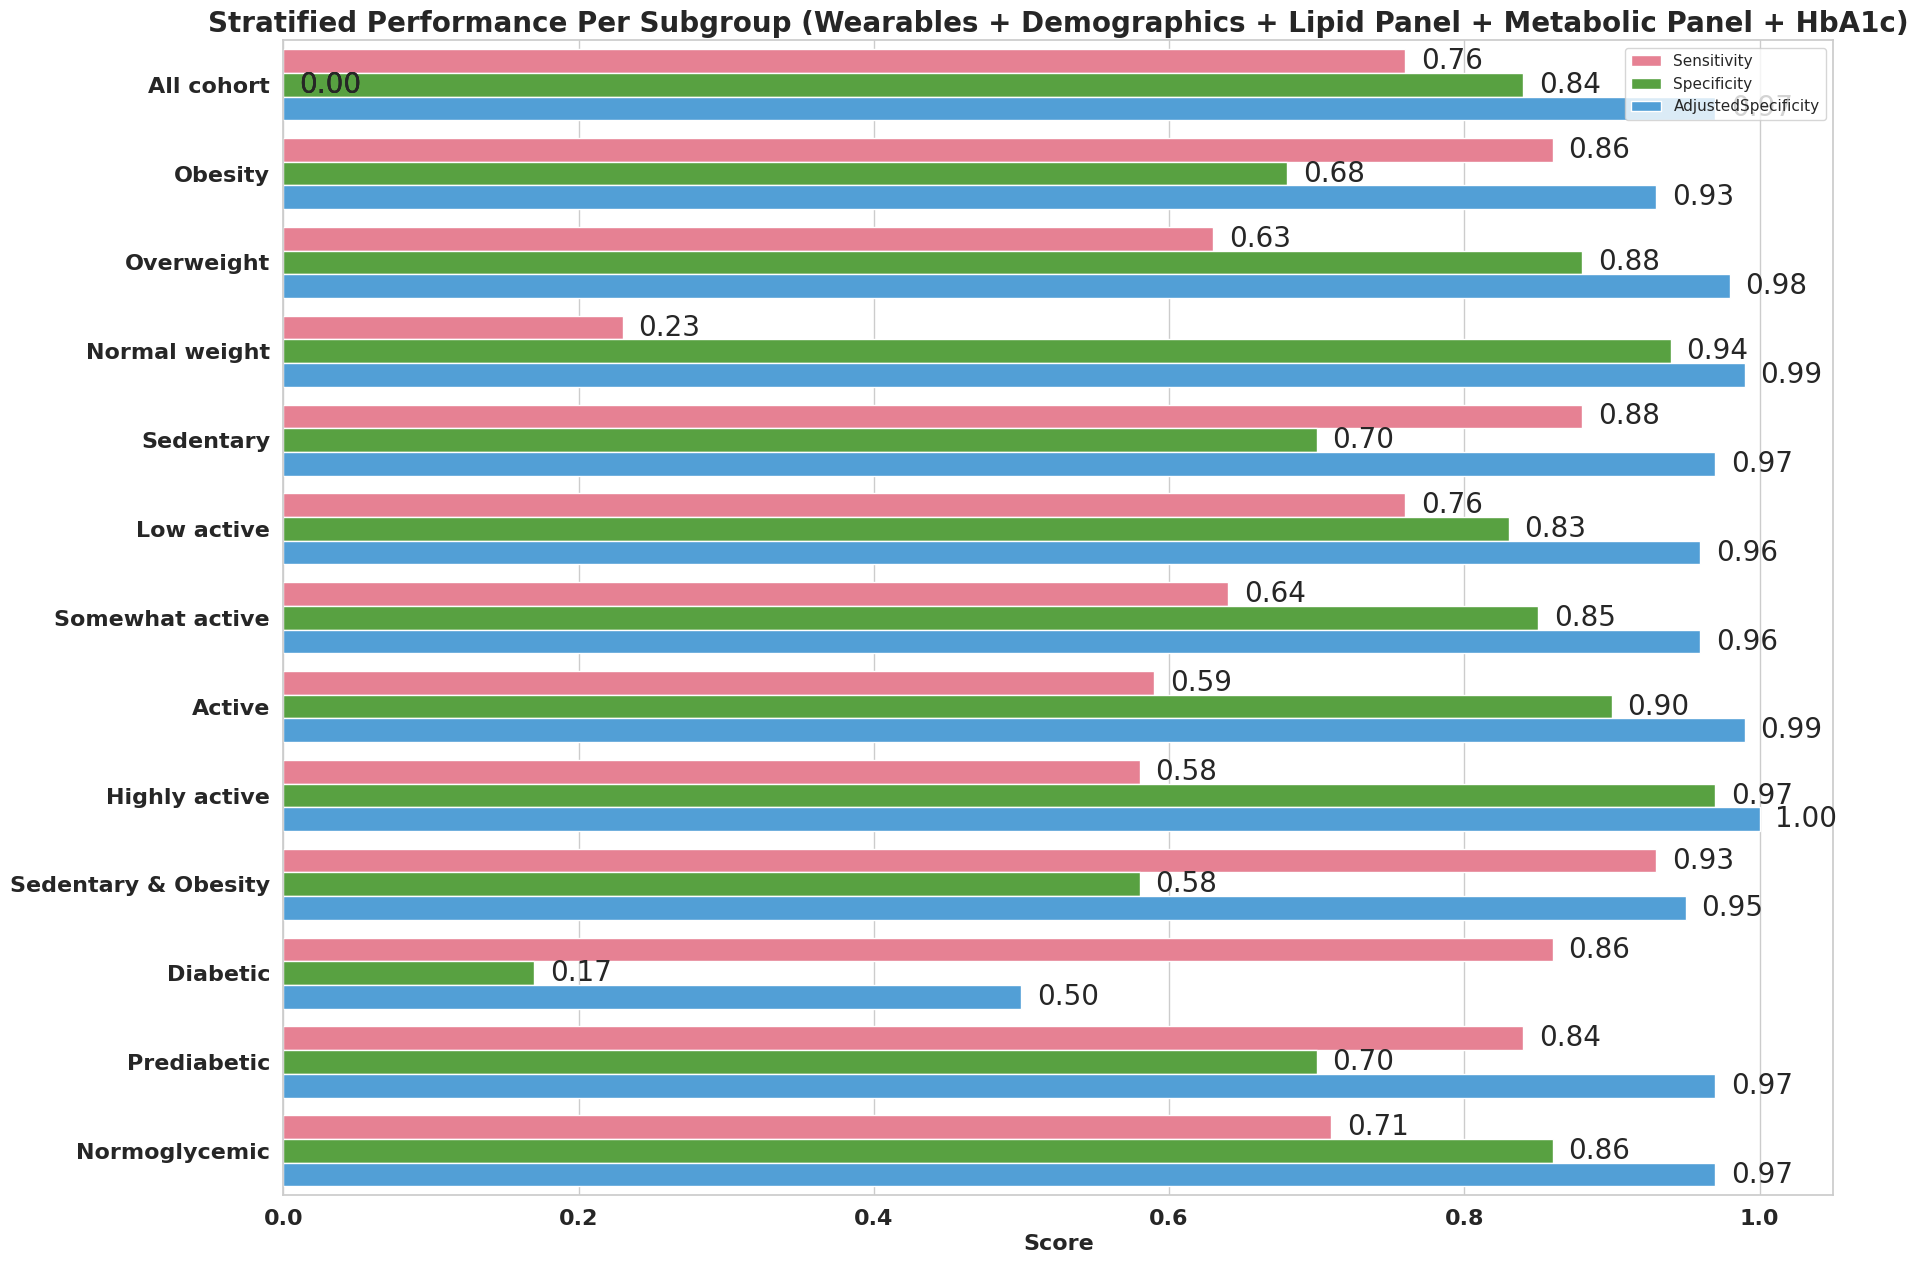

In [ ]:
#@title Do stratification for one experiment


# Concatenate all dataframes in the dictionary
homa_ir_prediction = dfs["EXP_11"]
# homa_ir_prediction = pd.concat(dfs.values(), ignore_index=True).reset_index(drop=True)
print(homa_ir_prediction.shape)

# Merge with labels, scores, and digital biomarkers
homa_ir_prediction_score_labels = homa_ir_prediction.merge(labels_and_scores_digital_biomarkers_cleaned, on='participant_id')
print(homa_ir_prediction_score_labels.shape)
homa_ir_prediction_score_labels.head()
# homa_ir_prediction_score_labels


# Apply Categorize based on HOMA-IR
homa_ir_prediction_score_labels['homa_ir_class_true'] = homa_ir_prediction_score_labels['true_values'].apply(categorize_homa_ir)
homa_ir_prediction_score_labels['homa_ir_class_predicted'] = homa_ir_prediction_score_labels['predicted_values'].apply(categorize_homa_ir)

# Apply the function to the BMI column to create a new column
homa_ir_prediction_score_labels['bmi_class'] = homa_ir_prediction_score_labels['bmi'].apply(categorize_bmi)

# Apply the function to the Step_Count column to create a new column
homa_ir_prediction_score_labels['physical_activity_class_steps'] = homa_ir_prediction_score_labels['STEPS_Daily_mean'].apply(categorize_activity)

# Aplpy Diabetes classification
homa_ir_prediction_score_labels['diabetes_class'] = homa_ir_prediction_score_labels['hba1c'].apply(categorize_diabetes)

stratified_perf_df = pd.DataFrame()

# print("All cohort")
subgroup_perf = calculate_performance(homa_ir_prediction_score_labels, subgroup="All cohort")
stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)

# print("\n Obese")
subgroup_perf = calculate_performance(homa_ir_prediction_score_labels[homa_ir_prediction_score_labels["bmi_class"] == "Obesity"], subgroup="Obesity")
stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)

# print("\n Overweight")
subgroup_perf = calculate_performance(homa_ir_prediction_score_labels[homa_ir_prediction_score_labels["bmi_class"] == "Overweight"], subgroup="Overweight")
stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)

# print("\n Normal weight")
subgroup_perf = calculate_performance(homa_ir_prediction_score_labels[homa_ir_prediction_score_labels["bmi_class"] == "Normal weight"], subgroup="Normal weight")
stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)

# print("\n Sedentary")
subgroup_perf = calculate_performance(homa_ir_prediction_score_labels[homa_ir_prediction_score_labels["physical_activity_class_steps"] == "Sedentary"], subgroup="Sedentary")
stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)

# print("\n Low active")
subgroup_perf = calculate_performance(homa_ir_prediction_score_labels[homa_ir_prediction_score_labels["physical_activity_class_steps"] == "Low active"], subgroup="Low active")
stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)


# print("\n Somewhat active")
subgroup_perf = calculate_performance(homa_ir_prediction_score_labels[homa_ir_prediction_score_labels["physical_activity_class_steps"] == "Somewhat active"], subgroup="Somewhat active")
stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)


# print("\n Active")
subgroup_perf = calculate_performance(homa_ir_prediction_score_labels[homa_ir_prediction_score_labels["physical_activity_class_steps"] == "Active"],  subgroup="Active")
stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)

# print("\n Highly active")
subgroup_perf = calculate_performance(homa_ir_prediction_score_labels[homa_ir_prediction_score_labels["physical_activity_class_steps"] == "Highly active"], subgroup="Highly active")
stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)



## Do joint group
# print("\n Sedentary & Obese")
subgroup_perf = calculate_performance(homa_ir_prediction_score_labels[
    (homa_ir_prediction_score_labels["physical_activity_class_steps"] == "Sedentary")
    &
    (homa_ir_prediction_score_labels["bmi_class"] == "Obesity")
    ], subgroup="Sedentary & Obesity")
stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)

# # Diabetes_Status
subgroup_perf = calculate_performance(homa_ir_prediction_score_labels[homa_ir_prediction_score_labels["diabetes_class"] == "Diabetic"], subgroup="Diabetic")
stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)

# print("\n Prediabetic")
subgroup_perf = calculate_performance(homa_ir_prediction_score_labels[homa_ir_prediction_score_labels["diabetes_class"] == "Prediabetic"], subgroup="Prediabetic")
stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)

# print("\n Normoglycemic")
subgroup_perf = calculate_performance(homa_ir_prediction_score_labels[homa_ir_prediction_score_labels["diabetes_class"] == "Normoglycemic"], subgroup="Normoglycemic")
stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)

display(stratified_perf_df)

# Melt the DataFrame to a long format
df_melted = stratified_perf_df.melt(id_vars='Subgroup', value_vars=['Sensitivity', 'Specificity', 'AdjustedSpecificity'],
                    var_name='Metric', value_name='Score')

display(df_melted)

# Set the style of the visualization
sns.set(style="whitegrid")

# Create a figure and axis
fig, ax = plt.subplots(figsize=(20, 15))

# Define a custom color palette
palette = sns.color_palette("husl", n_colors=df_melted['Metric'].nunique())


# Create a bar plot
bar_plot = sns.barplot(x='Score', y='Subgroup', hue='Metric', data=df_melted, ax=ax, palette=palette)


# Add values to each bar
for p in bar_plot.patches:
    bar_plot.annotate(format(p.get_width(), '.2f'),
                      (p.get_width() + 0.02, p.get_y() + p.get_height() / 2),
                      ha='left', va='center',
                      xytext=(-10, 0), textcoords='offset points', fontsize=20)

# Adjust legend title
plt.legend(title='')


plt.title('Stratified Performance Per Subgroup (Wearables + Demographics + Lipid Panel + Metabolic Panel + HbA1c)', fontsize=20, weight='bold')
plt.xlabel('Score', fontsize=16, weight='bold')
plt.ylabel('', fontsize=16, weight='bold')



# Customize the ticks on x and y axis
plt.xticks(fontsize=16, weight='bold')
plt.yticks(fontsize=16, weight='bold')
plt.show()


EXP_1
(1173, 4)
(1165, 159)
subgroup: All cohort Sensitivity: 0.603 Specificity: 0.809 AdjustedSpecificity: 0.936 tn: 700 fp: 165 fp_adjusted: 48
Dimension =  (1165, 163)


,participant_id,predicted_values,true_values,Experiment_ID,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,...,ascvd_risk,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary,Diabetes_Status,homa_ir_class_true,homa_ir_class_predicted,bmi_class,physical_activity_class_steps
89,13416,3.888096,0.53,EXP_1,77.402878,77.0,2.875816,14.678854,13.7330,4.083493,...,NaN,None,NaN,0.207039,0,Normoglycemic,0,1,Obesity,Low active
107,13533,3.553702,1.39,EXP_1,65.360000,65.0,2.374572,33.529189,33.7865,5.763363,...,NaN,None,NaN,0.185830,1,Normoglycemic,0,1,Obesity,Sedentary
126,13682,3.216861,0.62,EXP_1,75.814433,76.0,2.993360,16.265194,15.7760,3.644277,...,NaN,None,NaN,0.449601,0,Normoglycemic,0,1,Obesity,Low active
127,13684,3.293139,1.12,EXP_1,67.201835,68.0,2.814642,21.716717,21.6640,4.170199,...,NaN,None,NaN,0.736748,0,Normoglycemic,0,1,Obesity,Low active
131,13699,4.149108,1.22,EXP_1,77.881720,77.0,3.277604,19.084679,18.7695,6.289622,...,NaN,None,NaN,0.094271,0,Normoglycemic,0,1,Obesity,Sedentary
148,13790,3.899633,1.08,EXP_1,78.827586,79.0,2.779878,15.268419,14.8550,2.773114,...,NaN,None,NaN,0.233463,0,Normoglycemic,0,1,Obesity,Sedentary
149,13798,3.709531,1.46,EXP_1,71.153846,71.0,1.333718,15.987187,15.4875,3.364514,...,NaN,None,NaN,0.223048,0,Normoglycemic,0,1,Obesity,Somewhat active
191,55870,2.909530,0.66,EXP_1,71.257143,71.0,4.159565,62.205130,63.7720,15.867430,...,NaN,None,NaN,0.158290,0,Normoglycemic,0,1,Obesity,Low active
245,56040,2.937281,0.83,EXP_1,58.833333,59.0,2.959513,21.238897,20.8670,4.079245,...,NaN,None,NaN,0.263331,1,Normoglycemic,0,1,Overweight,Low active
329,56423,3.723235,1.26,EXP_1,60.723404,61.0,1.996812,31.760750,31.5340,4.281818,...,NaN,None,NaN,0.380952,0,Normoglycemic,0,1,Normal weight,Active


subgroup: Obesity Sensitivity: 0.761 Specificity: 0.482 AdjustedSpecificity: 0.787 tn: 122 fp: 131 fp_adjusted: 33
Dimension =  (458, 163)


,participant_id,predicted_values,true_values,Experiment_ID,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,...,ascvd_risk,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary,Diabetes_Status,homa_ir_class_true,homa_ir_class_predicted,bmi_class,physical_activity_class_steps
89,13416,3.888096,0.53,EXP_1,77.402878,77.0,2.875816,14.678854,13.7330,4.083493,...,NaN,None,NaN,0.207039,0,Normoglycemic,0,1,Obesity,Low active
107,13533,3.553702,1.39,EXP_1,65.360000,65.0,2.374572,33.529189,33.7865,5.763363,...,NaN,None,NaN,0.185830,1,Normoglycemic,0,1,Obesity,Sedentary
126,13682,3.216861,0.62,EXP_1,75.814433,76.0,2.993360,16.265194,15.7760,3.644277,...,NaN,None,NaN,0.449601,0,Normoglycemic,0,1,Obesity,Low active
127,13684,3.293139,1.12,EXP_1,67.201835,68.0,2.814642,21.716717,21.6640,4.170199,...,NaN,None,NaN,0.736748,0,Normoglycemic,0,1,Obesity,Low active
131,13699,4.149108,1.22,EXP_1,77.881720,77.0,3.277604,19.084679,18.7695,6.289622,...,NaN,None,NaN,0.094271,0,Normoglycemic,0,1,Obesity,Sedentary
148,13790,3.899633,1.08,EXP_1,78.827586,79.0,2.779878,15.268419,14.8550,2.773114,...,NaN,None,NaN,0.233463,0,Normoglycemic,0,1,Obesity,Sedentary
149,13798,3.709531,1.46,EXP_1,71.153846,71.0,1.333718,15.987187,15.4875,3.364514,...,NaN,None,NaN,0.223048,0,Normoglycemic,0,1,Obesity,Somewhat active
191,55870,2.909530,0.66,EXP_1,71.257143,71.0,4.159565,62.205130,63.7720,15.867430,...,NaN,None,NaN,0.158290,0,Normoglycemic,0,1,Obesity,Low active
347,56611,4.566972,1.31,EXP_1,62.203704,62.5,2.198347,28.585029,28.5300,6.527487,...,NaN,None,NaN,0.324983,1,Normoglycemic,0,1,Obesity,Low active
360,56691,2.966853,0.95,EXP_1,70.692308,71.0,1.911455,23.704694,24.2550,6.534843,...,NaN,None,NaN,0.971009,0,Normoglycemic,0,1,Obesity,Low active


subgroup: Overweight Sensitivity: 0.315 Specificity: 0.911 AdjustedSpecificity: 0.965 tn: 278 fp: 27 fp_adjusted: 10
Dimension =  (378, 163)


...

,participant_id,predicted_values,true_values,Experiment_ID,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,...,ascvd_risk,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary,Diabetes_Status,homa_ir_class_true,homa_ir_class_predicted,bmi_class,physical_activity_class_steps
459,57470,3.357673,1.34,EXP_1,67.400000,68.0,3.674821,7.300823,8.302,9.755408,...,NaN,None,NaN,0.301860,0,Normoglycemic,0,1,Overweight,Highly active
1113,73242,3.086603,0.99,EXP_1,80.813084,81.0,3.005881,27.150825,26.189,6.596052,...,NaN,None,NaN,0.181087,0,Normoglycemic,0,1,Obesity,Highly active


subgroup: Sedentary & Obesity Sensitivity: 0.94 Specificity: 0.141 AdjustedSpecificity: 0.45 tn: 9 fp: 55 fp_adjusted: 11
Dimension =  (147, 163)


,participant_id,predicted_values,true_values,Experiment_ID,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,...,ascvd_risk,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary,Diabetes_Status,homa_ir_class_true,homa_ir_class_predicted,bmi_class,physical_activity_class_steps
107,13533,3.553702,1.39,EXP_1,65.360000,65.0,2.374572,33.529189,33.7865,5.763363,...,NaN,None,NaN,0.185830,1,Normoglycemic,0,1,Obesity,Sedentary
131,13699,4.149108,1.22,EXP_1,77.881720,77.0,3.277604,19.084679,18.7695,6.289622,...,NaN,None,NaN,0.094271,0,Normoglycemic,0,1,Obesity,Sedentary
148,13790,3.899633,1.08,EXP_1,78.827586,79.0,2.779878,15.268419,14.8550,2.773114,...,NaN,None,NaN,0.233463,0,Normoglycemic,0,1,Obesity,Sedentary
433,57276,3.381184,1.15,EXP_1,74.676259,74.0,3.674904,23.734794,21.9465,8.130723,...,NaN,None,NaN,0.168729,0,Normoglycemic,0,1,Obesity,Sedentary
461,57472,3.187740,1.13,EXP_1,73.363636,74.0,3.800760,22.949364,23.5020,6.938473,...,NaN,None,NaN,0.128051,0,Normoglycemic,0,1,Obesity,Sedentary
556,58001,4.208014,1.27,EXP_1,76.830508,77.0,2.257112,12.007664,11.5580,1.960277,...,NaN,None,NaN,0.118636,1,Normoglycemic,0,1,Obesity,Sedentary
810,71086,4.334139,0.96,EXP_1,64.117647,65.0,3.584252,36.291261,35.8070,7.278590,...,NaN,None,NaN,0.183288,0,Prediabetic,0,1,Obesity,Sedentary
927,72035,3.644340,0.94,EXP_1,68.049020,68.0,1.732776,20.387867,21.7910,6.079120,...,NaN,None,NaN,0.139112,1,Normoglycemic,0,1,Obesity,Sedentary
942,72122,3.431630,1.26,EXP_1,75.435644,75.0,1.701131,13.147250,12.8785,1.882081,...,NaN,None,NaN,0.174717,0,Normoglycemic,0,1,Obesity,Sedentary
1071,72913,3.791376,1.20,EXP_1,69.540000,70.0,3.038844,30.251689,29.8250,22.836625,...,NaN,None,NaN,0.205714,0,Normoglycemic,0,1,Obesity,Sedentary


,Subgroup,Sensitivity,Specificity,AdjustedSpecificity
0,All cohort,0.60,0.81,0.94
1,Obesity,0.76,0.48,0.79
2,Overweight,0.32,0.91,0.96
3,Normal weight,0.09,0.98,0.99
4,Sedentary,0.89,0.47,0.82
5,Low active,0.60,0.77,0.91
6,Somewhat active,0.33,0.92,0.97
7,Active,0.29,0.93,0.97
8,Highly active,0.00,0.97,0.98
9,Sedentary & Obesity,0.94,0.14,0.45


,Subgroup,Metric,Score
0,All cohort,Sensitivity,0.60
1,Obesity,Sensitivity,0.76
2,Overweight,Sensitivity,0.32
3,Normal weight,Sensitivity,0.09
4,Sedentary,Sensitivity,0.89
5,Low active,Sensitivity,0.60
6,Somewhat active,Sensitivity,0.33
7,Active,Sensitivity,0.29
8,Highly active,Sensitivity,0.00
9,Sedentary & Obesity,Sensitivity,0.94


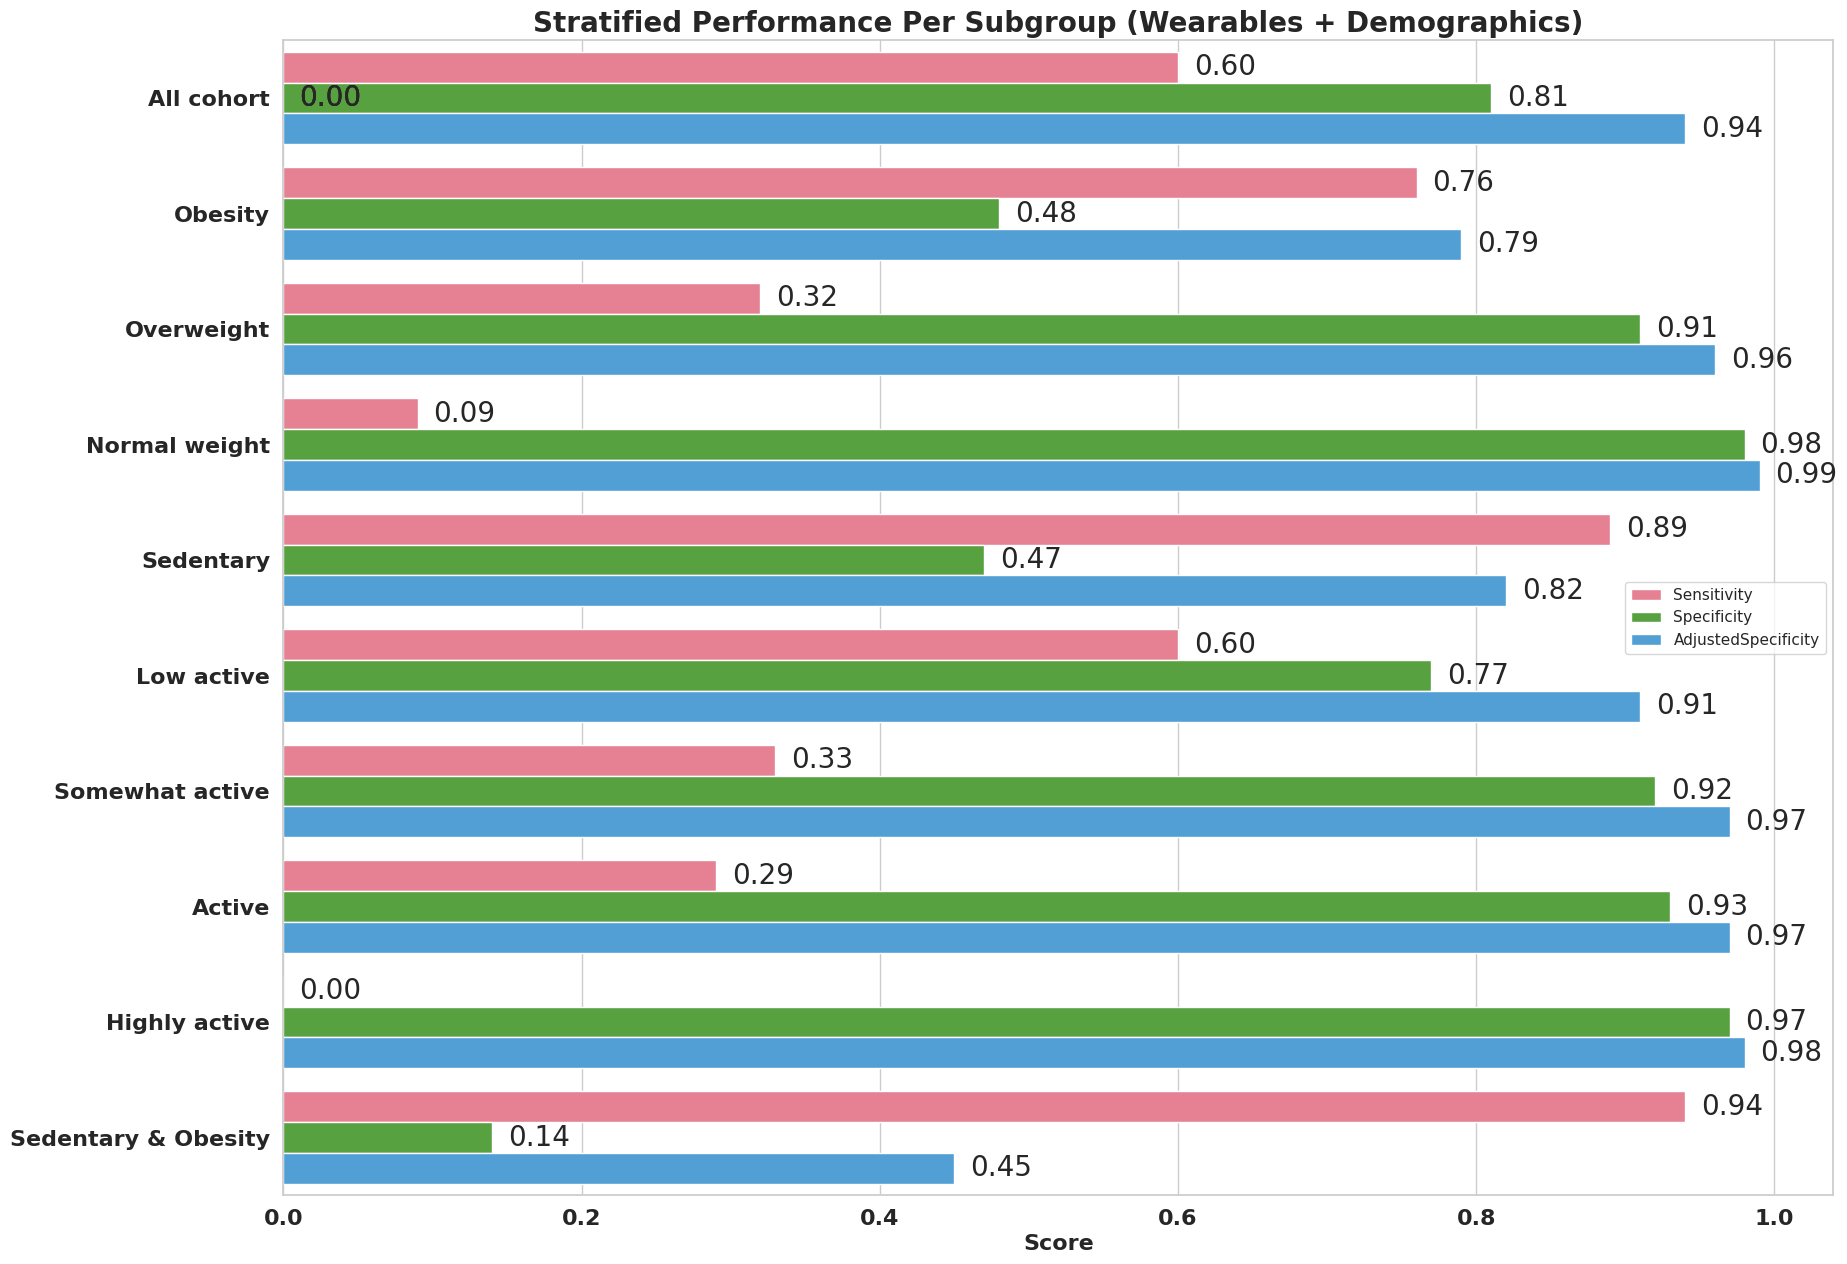

EXP_4
(1173, 4)
(1165, 159)
subgroup: All cohort Sensitivity: 0.65 Specificity: 0.762 AdjustedSpecificity: 0.909 tn: 659 fp: 206 fp_adjusted: 66
Dimension =  (1165, 163)


,participant_id,predicted_values,true_values,Experiment_ID,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,...,ascvd_risk,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary,Diabetes_Status,homa_ir_class_true,homa_ir_class_predicted,bmi_class,physical_activity_class_steps
2,12599,2.974366,0.67,EXP_4,65.168421,64.0,4.636302,42.677238,43.4890,10.082448,...,NaN,None,NaN,0.214918,0,Normoglycemic,0,1,Obesity,Somewhat active
10,12695,2.910835,1.11,EXP_4,65.194690,66.0,2.783630,28.858954,28.8125,6.840024,...,NaN,None,NaN,0.107239,1,Normoglycemic,0,1,Obesity,Low active
41,13086,2.938788,0.82,EXP_4,67.875000,68.0,2.167103,24.713469,25.2560,5.156692,...,NaN,None,NaN,0.204082,1,Normoglycemic,0,1,Obesity,Somewhat active
89,13416,2.987699,0.53,EXP_4,77.402878,77.0,2.875816,14.678854,13.7330,4.083493,...,NaN,None,NaN,0.207039,0,Normoglycemic,0,1,Obesity,Low active
107,13533,2.996971,1.39,EXP_4,65.360000,65.0,2.374572,33.529189,33.7865,5.763363,...,NaN,None,NaN,0.185830,1,Normoglycemic,0,1,Obesity,Sedentary
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1063,72816,3.317642,1.22,EXP_4,68.165217,68.0,1.596560,29.555606,28.7260,9.637907,...,NaN,None,NaN,0.185387,0,Normoglycemic,0,1,Obesity,Somewhat active
1071,72913,3.127784,1.20,EXP_4,69.540000,70.0,3.038844,30.251689,29.8250,22.836625,...,NaN,None,NaN,0.205714,0,Normoglycemic,0,1,Obesity,Sedentary
1089,73107,3.341362,1.45,EXP_4,70.386667,70.0,3.615379,36.990241,37.0445,11.965214,...,NaN,None,NaN,0.178571,0,Normoglycemic,0,1,Obesity,Sedentary
1113,73242,3.252289,0.99,EXP_4,80.813084,81.0,3.005881,27.150825,26.1890,6.596052,...,NaN,None,NaN,0.181087,0,Normoglycemic,0,1,Obesity,Highly active


subgroup: Obesity Sensitivity: 0.883 Specificity: 0.237 AdjustedSpecificity: 0.5 tn: 60 fp: 193 fp_adjusted: 60
Dimension =  (458, 163)


,participant_id,predicted_values,true_values,Experiment_ID,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,...,ascvd_risk,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary,Diabetes_Status,homa_ir_class_true,homa_ir_class_predicted,bmi_class,physical_activity_class_steps
2,12599,2.974366,0.67,EXP_4,65.168421,64.0,4.636302,42.677238,43.4890,10.082448,...,NaN,None,NaN,0.214918,0,Normoglycemic,0,1,Obesity,Somewhat active
10,12695,2.910835,1.11,EXP_4,65.194690,66.0,2.783630,28.858954,28.8125,6.840024,...,NaN,None,NaN,0.107239,1,Normoglycemic,0,1,Obesity,Low active
41,13086,2.938788,0.82,EXP_4,67.875000,68.0,2.167103,24.713469,25.2560,5.156692,...,NaN,None,NaN,0.204082,1,Normoglycemic,0,1,Obesity,Somewhat active
89,13416,2.987699,0.53,EXP_4,77.402878,77.0,2.875816,14.678854,13.7330,4.083493,...,NaN,None,NaN,0.207039,0,Normoglycemic,0,1,Obesity,Low active
107,13533,2.996971,1.39,EXP_4,65.360000,65.0,2.374572,33.529189,33.7865,5.763363,...,NaN,None,NaN,0.185830,1,Normoglycemic,0,1,Obesity,Sedentary
110,13559,3.094372,1.43,EXP_4,63.627273,63.0,3.474260,21.767624,21.4990,3.249787,...,NaN,None,NaN,0.277056,1,Normoglycemic,0,1,Obesity,Low active
126,13682,2.940636,0.62,EXP_4,75.814433,76.0,2.993360,16.265194,15.7760,3.644277,...,NaN,None,NaN,0.449601,0,Normoglycemic,0,1,Obesity,Low active
127,13684,3.091521,1.12,EXP_4,67.201835,68.0,2.814642,21.716717,21.6640,4.170199,...,NaN,None,NaN,0.736748,0,Normoglycemic,0,1,Obesity,Low active
148,13790,3.064629,1.08,EXP_4,78.827586,79.0,2.779878,15.268419,14.8550,2.773114,...,NaN,None,NaN,0.233463,0,Normoglycemic,0,1,Obesity,Sedentary
149,13798,3.136844,1.46,EXP_4,71.153846,71.0,1.333718,15.987187,15.4875,3.364514,...,NaN,None,NaN,0.223048,0,Normoglycemic,0,1,Obesity,Somewhat active


subgroup: Overweight Sensitivity: 0.192 Specificity: 0.957 AdjustedSpecificity: 0.98 tn: 292 fp: 13 fp_adjusted: 6
Dimension =  (378, 163)


...

,participant_id,predicted_values,true_values,Experiment_ID,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,...,ascvd_risk,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary,Diabetes_Status,homa_ir_class_true,homa_ir_class_predicted,bmi_class,physical_activity_class_steps
343,56570,2.975732,0.74,EXP_4,52.442105,52.0,1.719578,38.895649,35.7760,10.736114,...,NaN,None,NaN,0.345472,0,Normoglycemic,0,1,Obesity,Highly active
537,57855,3.316049,1.41,EXP_4,64.670000,65.0,2.368364,46.635850,46.7025,6.561954,...,NaN,None,NaN,0.201578,0,Normoglycemic,0,1,Obesity,Highly active
698,70413,2.953789,1.37,EXP_4,73.030303,73.0,3.318781,21.298928,20.5930,5.248963,...,NaN,None,NaN,0.280760,0,Normoglycemic,0,1,Obesity,Highly active
705,70433,2.976104,1.43,EXP_4,54.256198,54.0,1.934740,67.485050,65.1995,15.398912,...,NaN,None,NaN,0.319613,0,Normoglycemic,0,1,Obesity,Highly active
1113,73242,3.252289,0.99,EXP_4,80.813084,81.0,3.005881,27.150825,26.1890,6.596052,...,NaN,None,NaN,0.181087,0,Normoglycemic,0,1,Obesity,Highly active


subgroup: Sedentary & Obesity Sensitivity: 0.928 Specificity: 0.219 AdjustedSpecificity: 0.538 tn: 14 fp: 50 fp_adjusted: 12
Dimension =  (147, 163)


,participant_id,predicted_values,true_values,Experiment_ID,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,...,ascvd_risk,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary,Diabetes_Status,homa_ir_class_true,homa_ir_class_predicted,bmi_class,physical_activity_class_steps
107,13533,2.996971,1.39,EXP_4,65.360000,65.0,2.374572,33.529189,33.7865,5.763363,...,NaN,None,NaN,0.185830,1,Normoglycemic,0,1,Obesity,Sedentary
148,13790,3.064629,1.08,EXP_4,78.827586,79.0,2.779878,15.268419,14.8550,2.773114,...,NaN,None,NaN,0.233463,0,Normoglycemic,0,1,Obesity,Sedentary
421,57219,2.980550,0.75,EXP_4,60.040816,60.0,1.747780,66.261167,65.8545,8.116927,...,NaN,None,NaN,0.174308,0,Normoglycemic,0,1,Obesity,Sedentary
433,57276,2.949641,1.15,EXP_4,74.676259,74.0,3.674904,23.734794,21.9465,8.130723,...,NaN,None,NaN,0.168729,0,Normoglycemic,0,1,Obesity,Sedentary
517,57689,3.006855,1.13,EXP_4,60.254717,60.0,1.533582,19.015606,18.3590,3.165432,...,NaN,None,NaN,0.193512,1,Normoglycemic,0,1,Obesity,Sedentary
556,58001,3.347174,1.27,EXP_4,76.830508,77.0,2.257112,12.007664,11.5580,1.960277,...,NaN,None,NaN,0.118636,1,Normoglycemic,0,1,Obesity,Sedentary
731,70519,3.151160,1.48,EXP_4,63.157895,60.0,6.041912,NaN,NaN,NaN,...,NaN,None,NaN,0.280899,1,Normoglycemic,0,1,Obesity,Sedentary
810,71086,3.579058,0.96,EXP_4,64.117647,65.0,3.584252,36.291261,35.8070,7.278590,...,NaN,None,NaN,0.183288,0,Prediabetic,0,1,Obesity,Sedentary
927,72035,3.181338,0.94,EXP_4,68.049020,68.0,1.732776,20.387867,21.7910,6.079120,...,NaN,None,NaN,0.139112,1,Normoglycemic,0,1,Obesity,Sedentary
942,72122,3.223053,1.26,EXP_4,75.435644,75.0,1.701131,13.147250,12.8785,1.882081,...,NaN,None,NaN,0.174717,0,Normoglycemic,0,1,Obesity,Sedentary


,Subgroup,Sensitivity,Specificity,AdjustedSpecificity
0,All cohort,0.65,0.76,0.91
1,Obesity,0.88,0.24,0.50
2,Overweight,0.19,0.96,0.98
3,Normal weight,0.00,1.00,1.00
4,Sedentary,0.80,0.60,0.86
5,Low active,0.62,0.76,0.91
6,Somewhat active,0.53,0.76,0.91
7,Active,0.59,0.83,0.93
8,Highly active,0.33,0.90,0.94
9,Sedentary & Obesity,0.93,0.22,0.54


,Subgroup,Metric,Score
0,All cohort,Sensitivity,0.65
1,Obesity,Sensitivity,0.88
2,Overweight,Sensitivity,0.19
3,Normal weight,Sensitivity,0.00
4,Sedentary,Sensitivity,0.80
5,Low active,Sensitivity,0.62
6,Somewhat active,Sensitivity,0.53
7,Active,Sensitivity,0.59
8,Highly active,Sensitivity,0.33
9,Sedentary & Obesity,Sensitivity,0.93


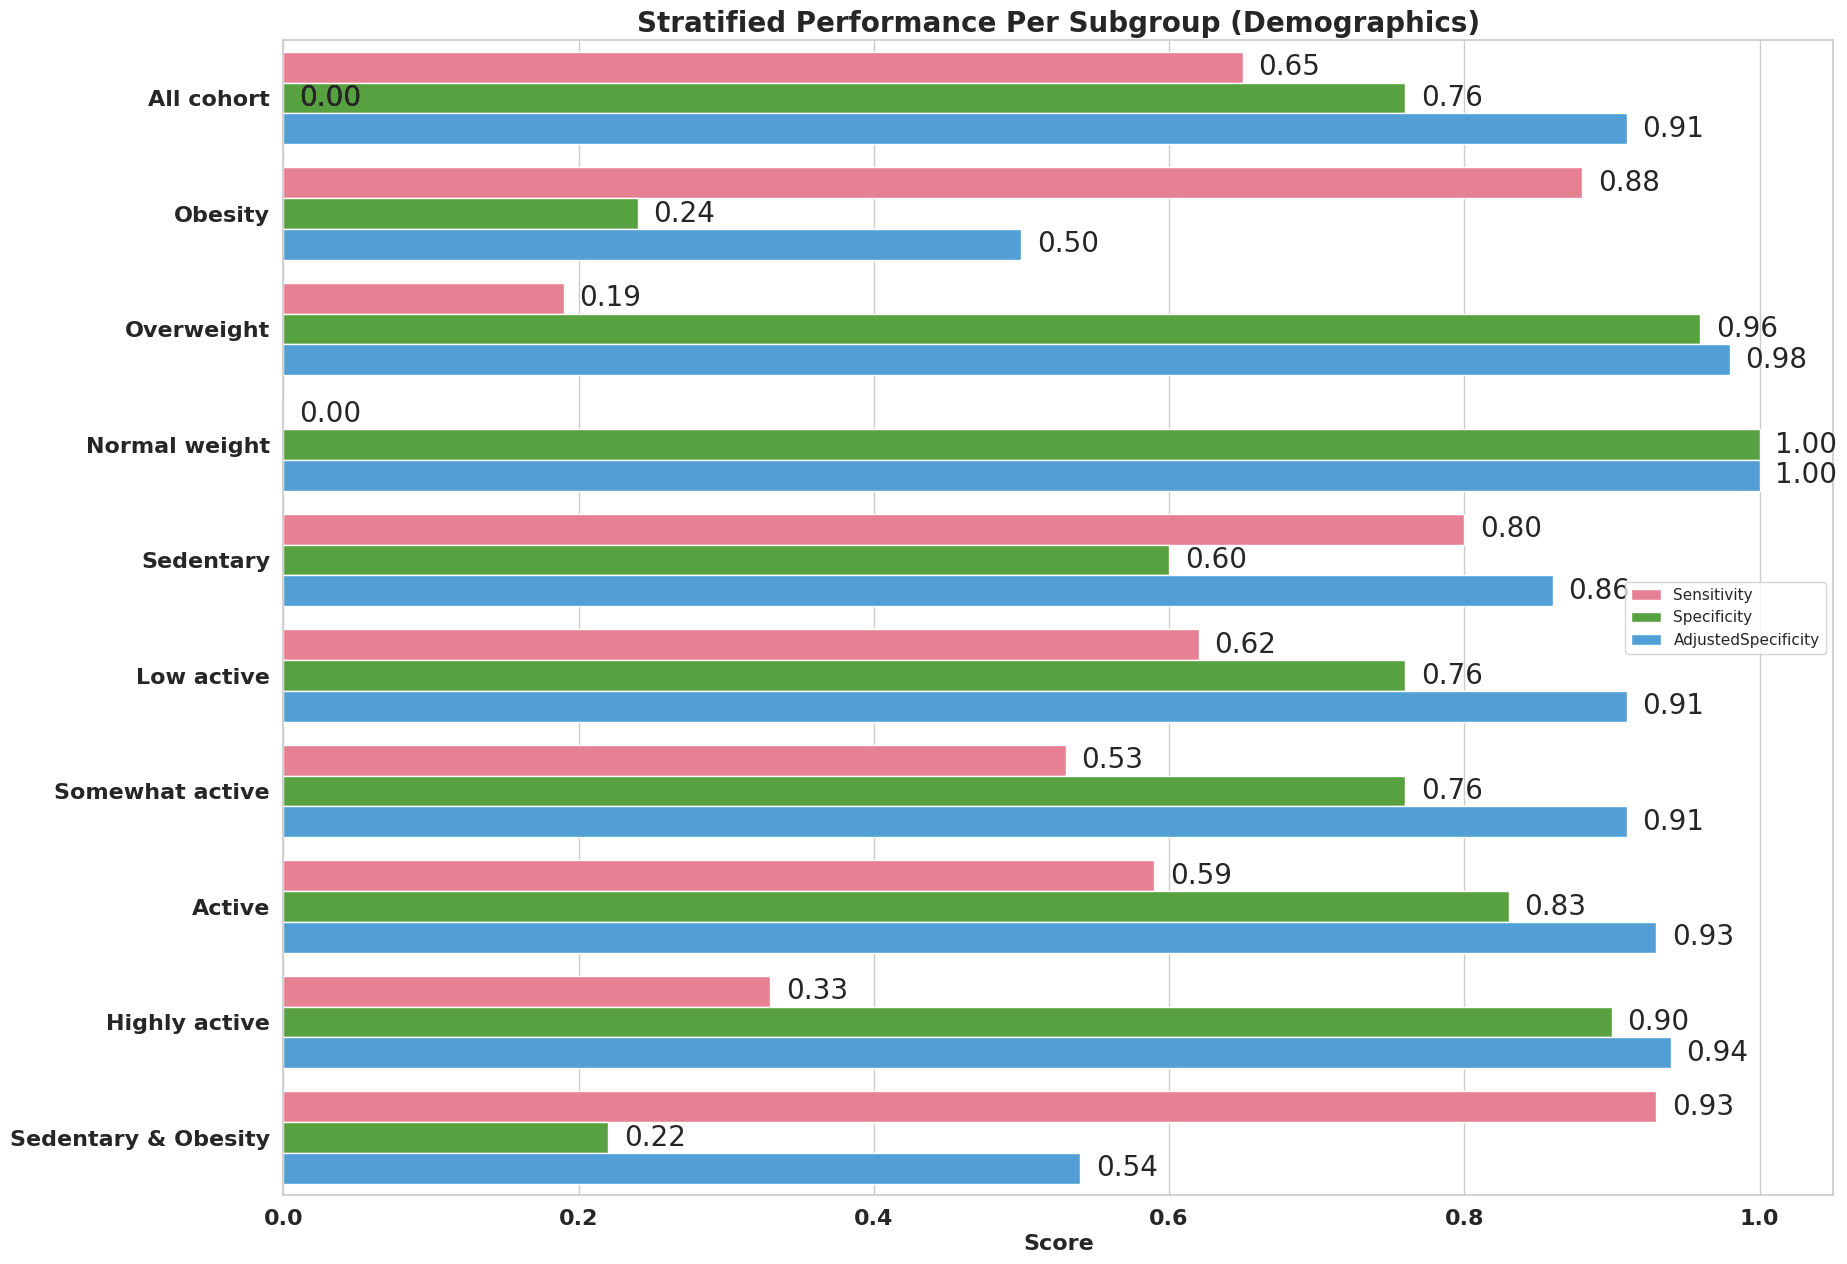

EXP_10
(1173, 4)
(1165, 159)
subgroup: All cohort Sensitivity: 0.71 Specificity: 0.832 AdjustedSpecificity: 0.965 tn: 720 fp: 145 fp_adjusted: 26
Dimension =  (1165, 163)


,participant_id,predicted_values,true_values,Experiment_ID,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,...,ascvd_risk,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary,Diabetes_Status,homa_ir_class_true,homa_ir_class_predicted,bmi_class,physical_activity_class_steps
131,13699,4.320502,1.22,EXP_10,77.881720,77.0,3.277604,19.084679,18.7695,6.289622,...,NaN,None,NaN,0.094271,0,Normoglycemic,0,1,Obesity,Sedentary
148,13790,3.798302,1.08,EXP_10,78.827586,79.0,2.779878,15.268419,14.8550,2.773114,...,NaN,None,NaN,0.233463,0,Normoglycemic,0,1,Obesity,Sedentary
149,13798,3.240050,1.46,EXP_10,71.153846,71.0,1.333718,15.987187,15.4875,3.364514,...,NaN,None,NaN,0.223048,0,Normoglycemic,0,1,Obesity,Somewhat active
347,56611,2.902563,1.31,EXP_10,62.203704,62.5,2.198347,28.585029,28.5300,6.527487,...,NaN,None,NaN,0.324983,1,Normoglycemic,0,1,Obesity,Low active
365,56770,3.292197,1.20,EXP_10,64.361446,64.0,2.603393,44.979500,44.9795,0.189948,...,NaN,None,NaN,0.183150,0,Normoglycemic,0,1,Overweight,Somewhat active
377,56883,3.136884,1.18,EXP_10,71.947368,72.0,6.800652,46.354786,36.1585,47.186600,...,NaN,None,NaN,0.502092,0,Normoglycemic,0,1,Normal weight,Low active
384,56921,3.878679,1.35,EXP_10,71.563636,72.0,2.168800,17.900327,18.0995,3.762211,...,NaN,None,NaN,0.267417,1,Normoglycemic,0,1,Obesity,Low active
408,57170,3.326247,1.44,EXP_10,67.330189,67.0,1.906446,27.489632,27.7990,6.866464,...,NaN,None,NaN,0.141228,0,Normoglycemic,0,1,Normal weight,Sedentary
459,57470,3.182319,1.34,EXP_10,67.400000,68.0,3.674821,7.300823,8.3020,9.755408,...,NaN,None,NaN,0.301860,0,Normoglycemic,0,1,Overweight,Highly active
480,57568,3.637474,1.49,EXP_10,82.628866,82.0,2.503136,19.980969,20.0855,4.612247,...,NaN,None,NaN,0.150376,0,Normoglycemic,0,1,Obesity,Somewhat active


subgroup: Obesity Sensitivity: 0.824 Specificity: 0.648 AdjustedSpecificity: 0.911 tn: 164 fp: 89 fp_adjusted: 16
Dimension =  (458, 163)


,participant_id,predicted_values,true_values,Experiment_ID,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,...,ascvd_risk,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary,Diabetes_Status,homa_ir_class_true,homa_ir_class_predicted,bmi_class,physical_activity_class_steps
131,13699,4.320502,1.22,EXP_10,77.881720,77.0,3.277604,19.084679,18.7695,6.289622,...,NaN,None,NaN,0.094271,0,Normoglycemic,0,1,Obesity,Sedentary
148,13790,3.798302,1.08,EXP_10,78.827586,79.0,2.779878,15.268419,14.8550,2.773114,...,NaN,None,NaN,0.233463,0,Normoglycemic,0,1,Obesity,Sedentary
149,13798,3.240050,1.46,EXP_10,71.153846,71.0,1.333718,15.987187,15.4875,3.364514,...,NaN,None,NaN,0.223048,0,Normoglycemic,0,1,Obesity,Somewhat active
347,56611,2.902563,1.31,EXP_10,62.203704,62.5,2.198347,28.585029,28.5300,6.527487,...,NaN,None,NaN,0.324983,1,Normoglycemic,0,1,Obesity,Low active
384,56921,3.878679,1.35,EXP_10,71.563636,72.0,2.168800,17.900327,18.0995,3.762211,...,NaN,None,NaN,0.267417,1,Normoglycemic,0,1,Obesity,Low active
480,57568,3.637474,1.49,EXP_10,82.628866,82.0,2.503136,19.980969,20.0855,4.612247,...,NaN,None,NaN,0.150376,0,Normoglycemic,0,1,Obesity,Somewhat active
536,57853,3.218373,1.34,EXP_10,75.474747,75.0,4.244658,34.240717,34.9030,10.327120,...,NaN,None,NaN,0.239144,0,Normoglycemic,0,1,Obesity,Low active
556,58001,3.229618,1.27,EXP_10,76.830508,77.0,2.257112,12.007664,11.5580,1.960277,...,NaN,None,NaN,0.118636,1,Normoglycemic,0,1,Obesity,Sedentary
942,72122,3.149027,1.26,EXP_10,75.435644,75.0,1.701131,13.147250,12.8785,1.882081,...,NaN,None,NaN,0.174717,0,Normoglycemic,0,1,Obesity,Sedentary
951,72151,7.099334,1.07,EXP_10,79.828571,79.0,3.869788,23.468922,27.0155,11.959427,...,NaN,None,NaN,0.551378,0,Normoglycemic,0,1,Obesity,Somewhat active


subgroup: Overweight Sensitivity: 0.548 Specificity: 0.872 AdjustedSpecificity: 0.974 tn: 266 fp: 39 fp_adjusted: 7
Dimension =  (378, 163)


...

,participant_id,predicted_values,true_values,Experiment_ID,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,...,ascvd_risk,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary,Diabetes_Status,homa_ir_class_true,homa_ir_class_predicted,bmi_class,physical_activity_class_steps
459,57470,3.182319,1.34,EXP_10,67.4,68.0,3.674821,7.300823,8.302,9.755408,...,NaN,None,NaN,0.30186,0,Normoglycemic,0,1,Overweight,Highly active


subgroup: Sedentary & Obesity Sensitivity: 0.94 Specificity: 0.422 AdjustedSpecificity: 0.818 tn: 27 fp: 37 fp_adjusted: 6
Dimension =  (147, 163)


,participant_id,predicted_values,true_values,Experiment_ID,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,...,ascvd_risk,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary,Diabetes_Status,homa_ir_class_true,homa_ir_class_predicted,bmi_class,physical_activity_class_steps
131,13699,4.320502,1.22,EXP_10,77.881720,77.0,3.277604,19.084679,18.7695,6.289622,...,NaN,None,NaN,0.094271,0,Normoglycemic,0,1,Obesity,Sedentary
148,13790,3.798302,1.08,EXP_10,78.827586,79.0,2.779878,15.268419,14.8550,2.773114,...,NaN,None,NaN,0.233463,0,Normoglycemic,0,1,Obesity,Sedentary
556,58001,3.229618,1.27,EXP_10,76.830508,77.0,2.257112,12.007664,11.5580,1.960277,...,NaN,None,NaN,0.118636,1,Normoglycemic,0,1,Obesity,Sedentary
942,72122,3.149027,1.26,EXP_10,75.435644,75.0,1.701131,13.147250,12.8785,1.882081,...,NaN,None,NaN,0.174717,0,Normoglycemic,0,1,Obesity,Sedentary
1071,72913,2.973864,1.20,EXP_10,69.540000,70.0,3.038844,30.251689,29.8250,22.836625,...,NaN,None,NaN,0.205714,0,Normoglycemic,0,1,Obesity,Sedentary
1089,73107,2.965507,1.45,EXP_10,70.386667,70.0,3.615379,36.990241,37.0445,11.965214,...,NaN,None,NaN,0.178571,0,Normoglycemic,0,1,Obesity,Sedentary


,Subgroup,Sensitivity,Specificity,AdjustedSpecificity
0,All cohort,0.71,0.83,0.96
1,Obesity,0.82,0.65,0.91
2,Overweight,0.55,0.87,0.97
3,Normal weight,0.18,0.94,0.99
4,Sedentary,0.88,0.58,0.90
5,Low active,0.69,0.83,0.97
6,Somewhat active,0.55,0.87,0.96
7,Active,0.59,0.93,0.98
8,Highly active,0.42,0.96,0.99
9,Sedentary & Obesity,0.94,0.42,0.82


,Subgroup,Metric,Score
0,All cohort,Sensitivity,0.71
1,Obesity,Sensitivity,0.82
2,Overweight,Sensitivity,0.55
3,Normal weight,Sensitivity,0.18
4,Sedentary,Sensitivity,0.88
5,Low active,Sensitivity,0.69
6,Somewhat active,Sensitivity,0.55
7,Active,Sensitivity,0.59
8,Highly active,Sensitivity,0.42
9,Sedentary & Obesity,Sensitivity,0.94


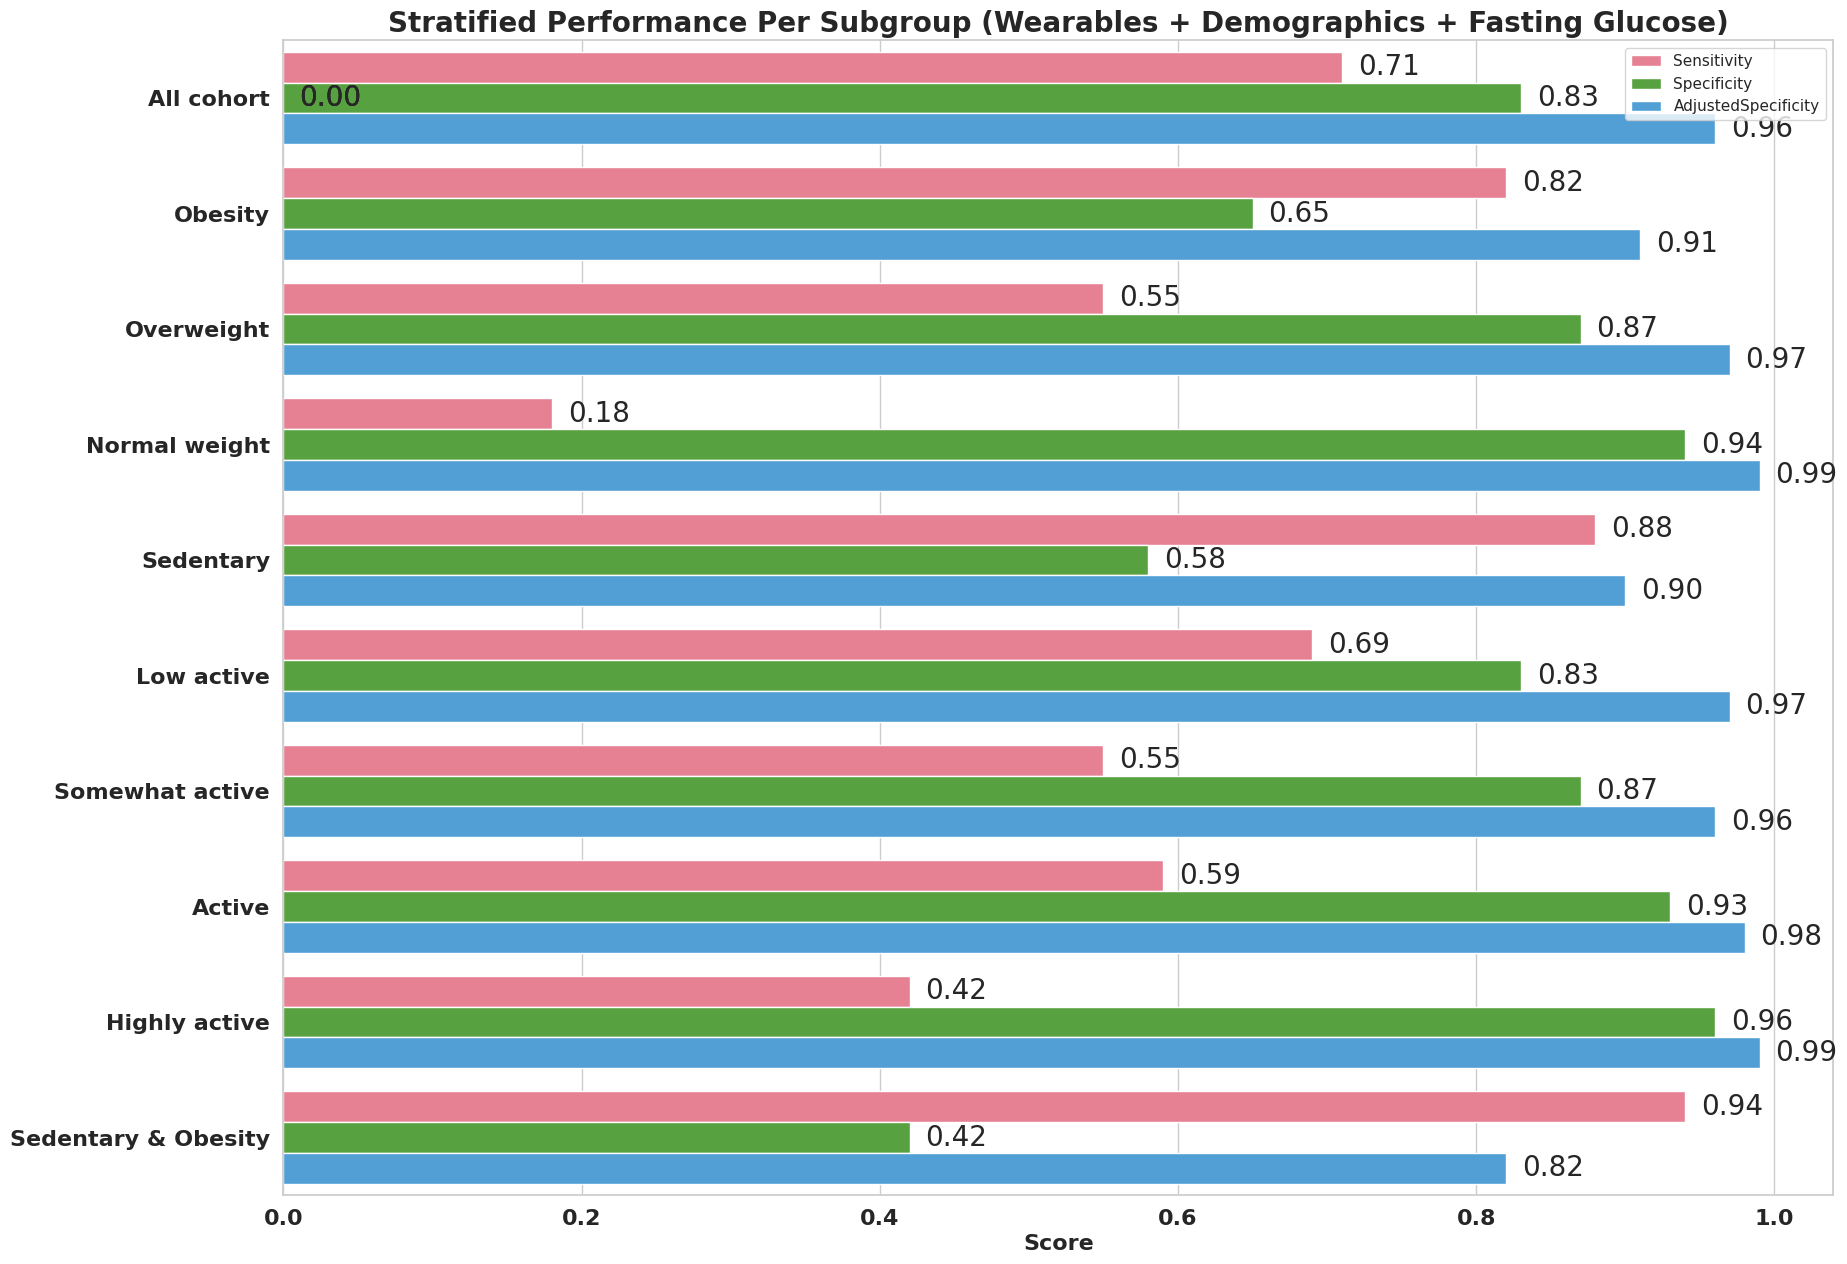

EXP_11
(1173, 4)
(1165, 159)
subgroup: All cohort Sensitivity: 0.76 Specificity: 0.84 AdjustedSpecificity: 0.971 tn: 727 fp: 138 fp_adjusted: 22
Dimension =  (1165, 163)


,participant_id,predicted_values,true_values,Experiment_ID,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,...,ascvd_risk,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary,Diabetes_Status,homa_ir_class_true,homa_ir_class_predicted,bmi_class,physical_activity_class_steps
131,13699,3.346045,1.22,EXP_11,77.881720,77.0,3.277604,19.084679,18.7695,6.289622,...,NaN,None,NaN,0.094271,0,Normoglycemic,0,1,Obesity,Sedentary
152,13819,2.921984,0.72,EXP_11,57.797980,58.0,2.146795,16.404041,16.1420,4.429918,...,NaN,None,NaN,0.242692,1,Normoglycemic,0,1,Overweight,Low active
191,55870,2.952543,0.66,EXP_11,71.257143,71.0,4.159565,62.205130,63.7720,15.867430,...,NaN,None,NaN,0.158290,0,Normoglycemic,0,1,Obesity,Low active
328,56418,3.009351,0.77,EXP_11,61.970297,62.0,2.192050,29.781350,30.0265,6.525426,...,NaN,None,NaN,0.204082,1,Normoglycemic,0,1,Obesity,Low active
377,56883,3.488820,1.18,EXP_11,71.947368,72.0,6.800652,46.354786,36.1585,47.186600,...,NaN,None,NaN,0.502092,0,Normoglycemic,0,1,Normal weight,Low active
384,56921,3.275285,1.35,EXP_11,71.563636,72.0,2.168800,17.900327,18.0995,3.762211,...,NaN,None,NaN,0.267417,1,Normoglycemic,0,1,Obesity,Low active
494,57609,3.029352,1.46,EXP_11,63.689320,64.0,1.848027,80.528835,80.7250,10.486620,...,NaN,None,NaN,0.128968,0,Normoglycemic,0,1,Normal weight,Somewhat active
497,57628,3.020782,1.17,EXP_11,64.427350,65.0,2.601803,54.463519,52.7555,14.056547,...,NaN,None,NaN,0.091185,0,Prediabetic,0,1,Obesity,Low active
510,57672,3.234647,1.13,EXP_11,61.552381,62.0,2.573256,46.233162,49.0370,14.473240,...,NaN,None,NaN,0.209314,0,Normoglycemic,0,1,Overweight,Somewhat active
536,57853,3.461545,1.34,EXP_11,75.474747,75.0,4.244658,34.240717,34.9030,10.327120,...,NaN,None,NaN,0.239144,0,Normoglycemic,0,1,Obesity,Low active


subgroup: Obesity Sensitivity: 0.863 Specificity: 0.676 AdjustedSpecificity: 0.934 tn: 171 fp: 82 fp_adjusted: 12
Dimension =  (458, 163)


,participant_id,predicted_values,true_values,Experiment_ID,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,...,ascvd_risk,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary,Diabetes_Status,homa_ir_class_true,homa_ir_class_predicted,bmi_class,physical_activity_class_steps
131,13699,3.346045,1.22,EXP_11,77.881720,77.0,3.277604,19.084679,18.7695,6.289622,...,NaN,None,NaN,0.094271,0,Normoglycemic,0,1,Obesity,Sedentary
191,55870,2.952543,0.66,EXP_11,71.257143,71.0,4.159565,62.205130,63.7720,15.867430,...,NaN,None,NaN,0.158290,0,Normoglycemic,0,1,Obesity,Low active
328,56418,3.009351,0.77,EXP_11,61.970297,62.0,2.192050,29.781350,30.0265,6.525426,...,NaN,None,NaN,0.204082,1,Normoglycemic,0,1,Obesity,Low active
384,56921,3.275285,1.35,EXP_11,71.563636,72.0,2.168800,17.900327,18.0995,3.762211,...,NaN,None,NaN,0.267417,1,Normoglycemic,0,1,Obesity,Low active
497,57628,3.020782,1.17,EXP_11,64.427350,65.0,2.601803,54.463519,52.7555,14.056547,...,NaN,None,NaN,0.091185,0,Prediabetic,0,1,Obesity,Low active
536,57853,3.461545,1.34,EXP_11,75.474747,75.0,4.244658,34.240717,34.9030,10.327120,...,NaN,None,NaN,0.239144,0,Normoglycemic,0,1,Obesity,Low active
678,70355,3.664602,1.23,EXP_11,52.941606,52.0,3.448770,34.864829,34.6030,7.471314,...,NaN,None,NaN,0.714286,1,Normoglycemic,0,1,Obesity,Somewhat active
951,72151,6.946205,1.07,EXP_11,79.828571,79.0,3.869788,23.468922,27.0155,11.959427,...,NaN,None,NaN,0.551378,0,Normoglycemic,0,1,Obesity,Somewhat active
1057,72772,3.709178,1.42,EXP_11,77.415842,77.0,2.563686,19.213984,18.5970,4.285859,...,NaN,None,NaN,0.147917,0,Normoglycemic,0,1,Obesity,Low active
1063,72816,2.950277,1.22,EXP_11,68.165217,68.0,1.596560,29.555606,28.7260,9.637907,...,NaN,None,NaN,0.185387,0,Normoglycemic,0,1,Obesity,Somewhat active


subgroup: Overweight Sensitivity: 0.63 Specificity: 0.875 AdjustedSpecificity: 0.978 tn: 267 fp: 38 fp_adjusted: 6
Dimension =  (378, 163)


...

,participant_id,predicted_values,true_values,Experiment_ID,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,...,ascvd_risk,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary,Diabetes_Status,homa_ir_class_true,homa_ir_class_predicted,bmi_class,physical_activity_class_steps


subgroup: Sedentary & Obesity Sensitivity: 0.928 Specificity: 0.578 AdjustedSpecificity: 0.949 tn: 37 fp: 27 fp_adjusted: 2
Dimension =  (147, 163)


,participant_id,predicted_values,true_values,Experiment_ID,RHR_FreeLiving_mean,RHR_FreeLiving_median,RHR_FreeLiving_std,HRV_FreeLiving_mean,HRV_FreeLiving_median,HRV_FreeLiving_std,...,ascvd_risk,ascvd_risk_category,optimal_ascvd_risk,apri,hypertension_binary,Diabetes_Status,homa_ir_class_true,homa_ir_class_predicted,bmi_class,physical_activity_class_steps
131,13699,3.346045,1.22,EXP_11,77.881720,77.0,3.277604,19.084679,18.7695,6.289622,...,NaN,None,NaN,0.094271,0,Normoglycemic,0,1,Obesity,Sedentary
1089,73107,3.348786,1.45,EXP_11,70.386667,70.0,3.615379,36.990241,37.0445,11.965214,...,NaN,None,NaN,0.178571,0,Normoglycemic,0,1,Obesity,Sedentary


,Subgroup,Sensitivity,Specificity,AdjustedSpecificity
0,All cohort,0.76,0.84,0.97
1,Obesity,0.86,0.68,0.93
2,Overweight,0.63,0.88,0.98
3,Normal weight,0.23,0.94,0.99
4,Sedentary,0.88,0.70,0.97
5,Low active,0.76,0.83,0.96
6,Somewhat active,0.64,0.85,0.96
7,Active,0.59,0.90,0.99
8,Highly active,0.58,0.97,1.00
9,Sedentary & Obesity,0.93,0.58,0.95


,Subgroup,Metric,Score
0,All cohort,Sensitivity,0.76
1,Obesity,Sensitivity,0.86
2,Overweight,Sensitivity,0.63
3,Normal weight,Sensitivity,0.23
4,Sedentary,Sensitivity,0.88
5,Low active,Sensitivity,0.76
6,Somewhat active,Sensitivity,0.64
7,Active,Sensitivity,0.59
8,Highly active,Sensitivity,0.58
9,Sedentary & Obesity,Sensitivity,0.93


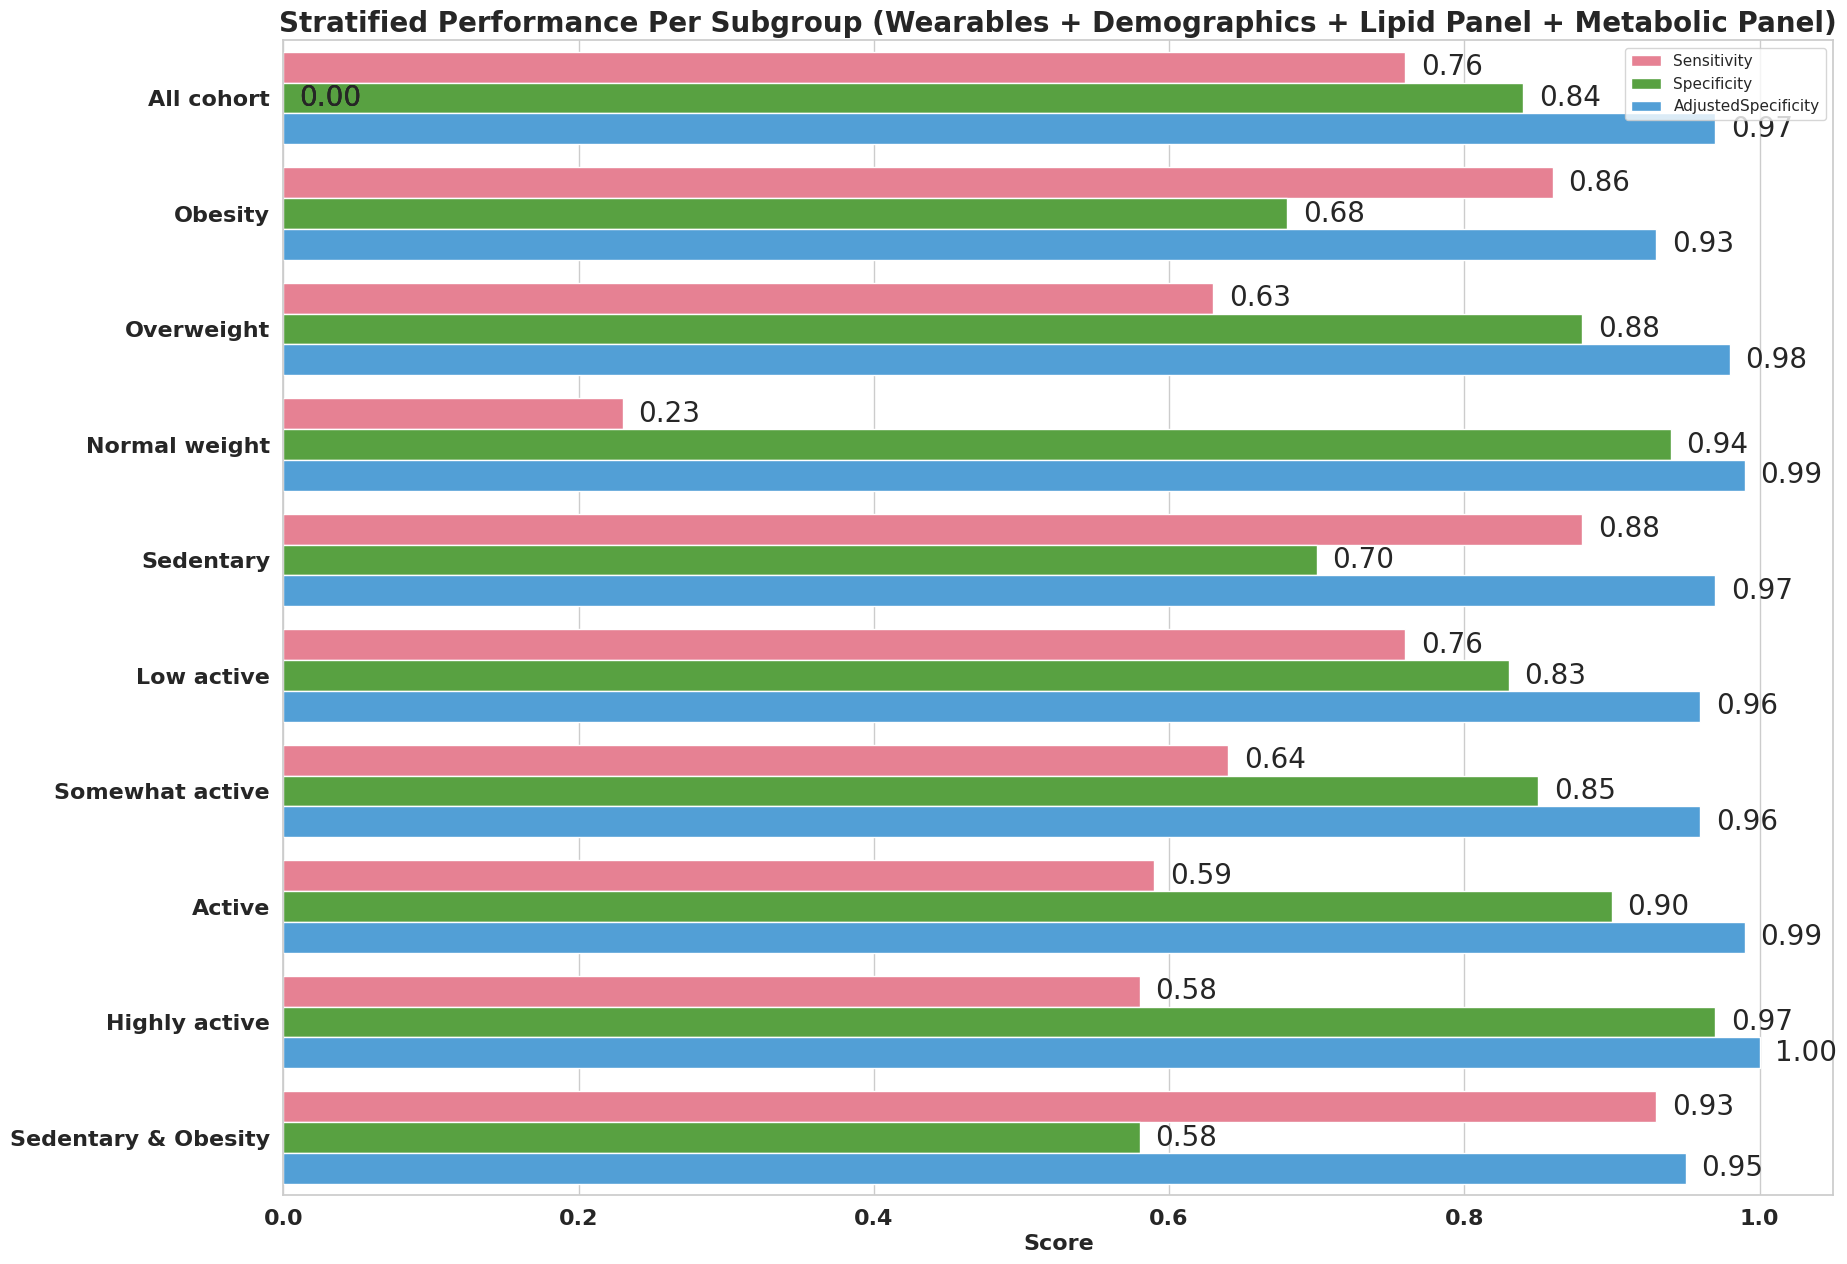

In [ ]:
#@title Perform Startification analysis for all experiments

experiments = {"EXP_1": "Wearables + Demographics",
               "EXP_4": "Demographics",
               "EXP_10": "Wearables + Demographics + Fasting Glucose",
               "EXP_11": "Wearables + Demographics + Lipid Panel + Metabolic Panel"}
for exp in experiments:
  print(exp)

  # Concatenate all dataframes in the dictionary
  homa_ir_prediction = dfs[exp]
  # homa_ir_prediction = pd.concat(dfs.values(), ignore_index=True).reset_index(drop=True)
  print(homa_ir_prediction.shape)

  # Merge with labels, scores, and digital biomarkers
  homa_ir_prediction_score_labels = homa_ir_prediction.merge(labels_and_scores_digital_biomarkers_cleaned, on='participant_id')
  print(homa_ir_prediction_score_labels.shape)
  homa_ir_prediction_score_labels.head()
  # homa_ir_prediction_score_labels


  # Apply Categorize based on HOMA-IR
  homa_ir_prediction_score_labels['homa_ir_class_true'] = homa_ir_prediction_score_labels['true_values'].apply(categorize_homa_ir)
  homa_ir_prediction_score_labels['homa_ir_class_predicted'] = homa_ir_prediction_score_labels['predicted_values'].apply(categorize_homa_ir)

  # Apply the function to the BMI column to create a new column
  homa_ir_prediction_score_labels['bmi_class'] = homa_ir_prediction_score_labels['bmi'].apply(categorize_bmi)

  # Apply the function to the Step_Count column to create a new column
  homa_ir_prediction_score_labels['physical_activity_class_steps'] = homa_ir_prediction_score_labels['STEPS_Daily_mean'].apply(categorize_activity)

  stratified_perf_df = pd.DataFrame()
  # print("All cohort")
  subgroup_perf = calculate_performance(homa_ir_prediction_score_labels, subgroup="All cohort")
  stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)

  # print("\n Obese")
  subgroup_perf = calculate_performance(homa_ir_prediction_score_labels[homa_ir_prediction_score_labels["bmi_class"] == "Obesity"], subgroup="Obesity")
  stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)

  # print("\n Overweight")
  subgroup_perf = calculate_performance(homa_ir_prediction_score_labels[homa_ir_prediction_score_labels["bmi_class"] == "Overweight"], subgroup="Overweight")
  stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)

  # print("\n Normal weight")
  subgroup_perf = calculate_performance(homa_ir_prediction_score_labels[homa_ir_prediction_score_labels["bmi_class"] == "Normal weight"], subgroup="Normal weight")
  stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)


  # print("\n Sedentary")
  subgroup_perf = calculate_performance(homa_ir_prediction_score_labels[homa_ir_prediction_score_labels["physical_activity_class_steps"] == "Sedentary"], subgroup="Sedentary")
  stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)

  # print("\n Low active")
  subgroup_perf = calculate_performance(homa_ir_prediction_score_labels[homa_ir_prediction_score_labels["physical_activity_class_steps"] == "Low active"], subgroup="Low active")
  stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)


  # print("\n Somewhat active")
  subgroup_perf = calculate_performance(homa_ir_prediction_score_labels[homa_ir_prediction_score_labels["physical_activity_class_steps"] == "Somewhat active"], subgroup="Somewhat active")
  stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)


  # print("\n Active")
  subgroup_perf = calculate_performance(homa_ir_prediction_score_labels[homa_ir_prediction_score_labels["physical_activity_class_steps"] == "Active"],  subgroup="Active")
  stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)

  # print("\n Highly active")
  subgroup_perf = calculate_performance(homa_ir_prediction_score_labels[homa_ir_prediction_score_labels["physical_activity_class_steps"] == "Highly active"], subgroup="Highly active")
  stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)



  ## Do joint group
  # print("\n Sedentary & Obese")
  subgroup_perf = calculate_performance(homa_ir_prediction_score_labels[
      (homa_ir_prediction_score_labels["physical_activity_class_steps"] == "Sedentary")
      &
      (homa_ir_prediction_score_labels["bmi_class"] == "Obesity")
      ], subgroup="Sedentary & Obesity")
  stratified_perf_df = pd.concat([stratified_perf_df, subgroup_perf], ignore_index=True)

  display(stratified_perf_df)

  # Melt the DataFrame to a long format
  df_melted = stratified_perf_df.melt(id_vars='Subgroup', value_vars=['Sensitivity', 'Specificity', 'AdjustedSpecificity'],
                      var_name='Metric', value_name='Score')

  display(df_melted)

  # Set the style of the visualization
  sns.set(style="whitegrid")

  # Create a figure and axis
  fig, ax = plt.subplots(figsize=(20, 15))

  # Define a custom color palette
  palette = sns.color_palette("husl", n_colors=df_melted['Metric'].nunique())


  # Create a bar plot
  bar_plot = sns.barplot(x='Score', y='Subgroup', hue='Metric', data=df_melted, ax=ax, palette=palette)


  # Add values to each bar
  for p in bar_plot.patches:
      bar_plot.annotate(format(p.get_width(), '.2f'),
                        (p.get_width() + 0.02, p.get_y() + p.get_height() / 2),
                        ha='left', va='center',
                        xytext=(-10, 0), textcoords='offset points', fontsize=20)

  # Adjust legend title
  plt.legend(title='')


  plt.title('Stratified Performance Per Subgroup (' + experiments[exp] + ')', fontsize=20, weight='bold')
  plt.xlabel('Score', fontsize=16, weight='bold')
  plt.ylabel('', fontsize=16, weight='bold')



  # Customize the ticks on x and y axis
  plt.xticks(fontsize=16, weight='bold')
  plt.yticks(fontsize=16, weight='bold')
  plt.show()


In [ ]:
#@title Calculate # of ppl per class
homa_ir_prediction_score_labels["Diabetes_Status"].value_counts()

,count
Diabetes_Status,
Normoglycemic,972
Prediabetic,159
Diabetic,34


<Figure size 600x800 with 0 Axes>

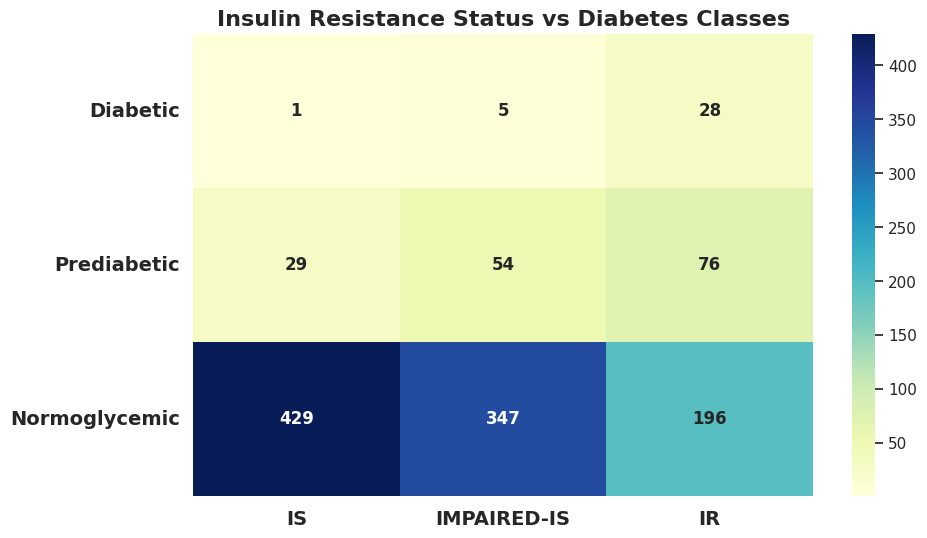

<Figure size 600x800 with 0 Axes>

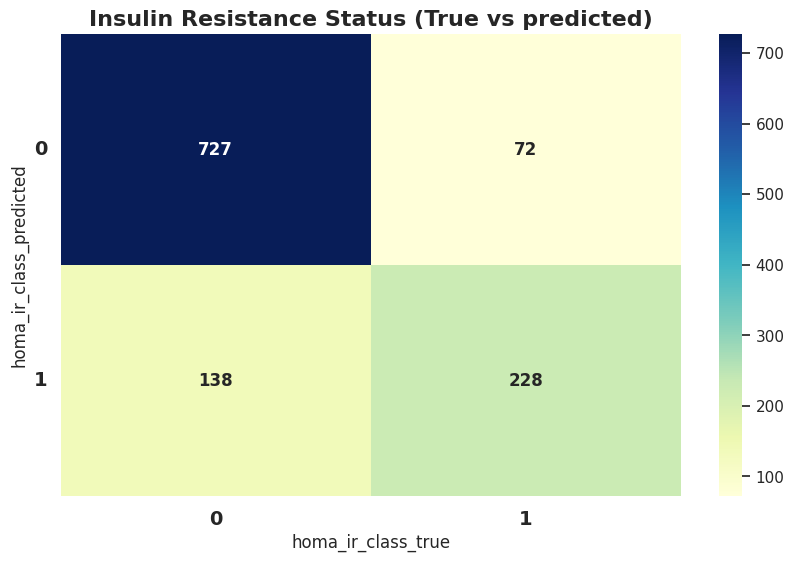

<Figure size 600x800 with 0 Axes>

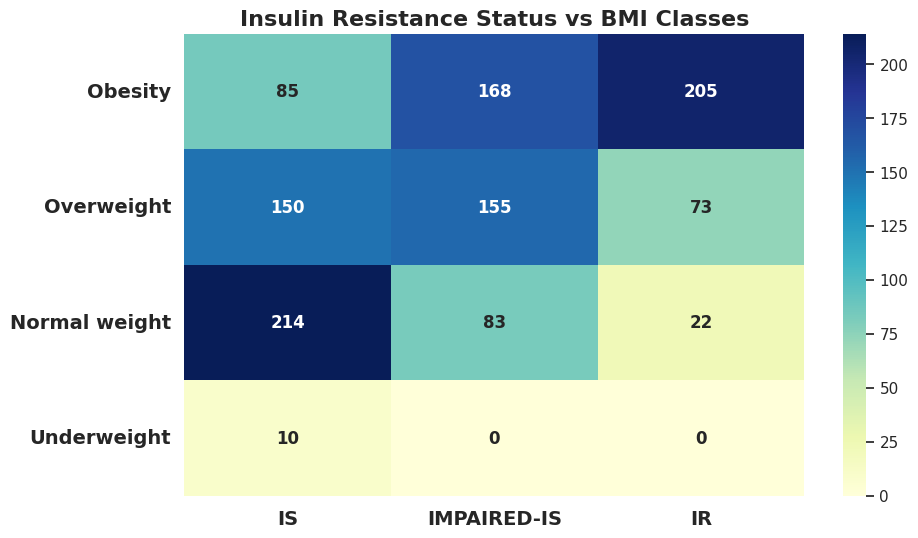

<Figure size 600x800 with 0 Axes>

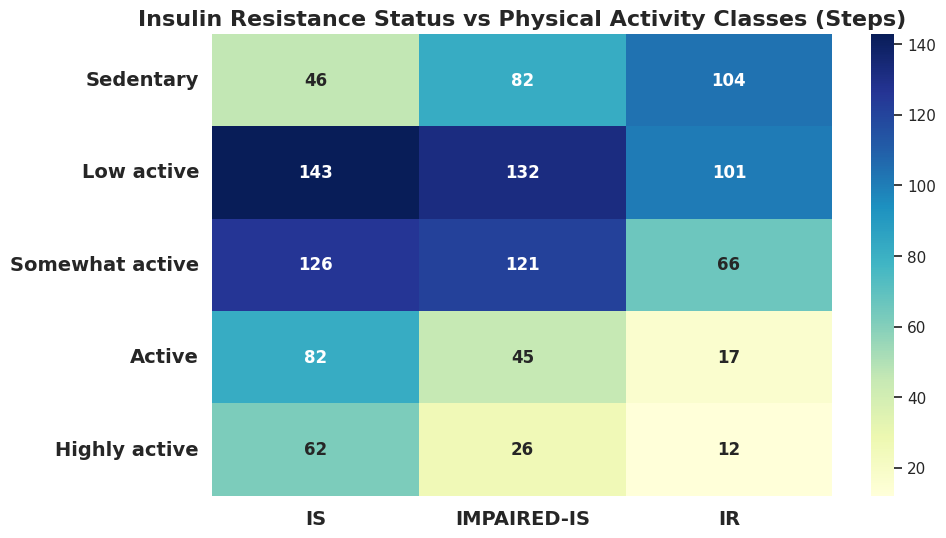

<Figure size 600x800 with 0 Axes>

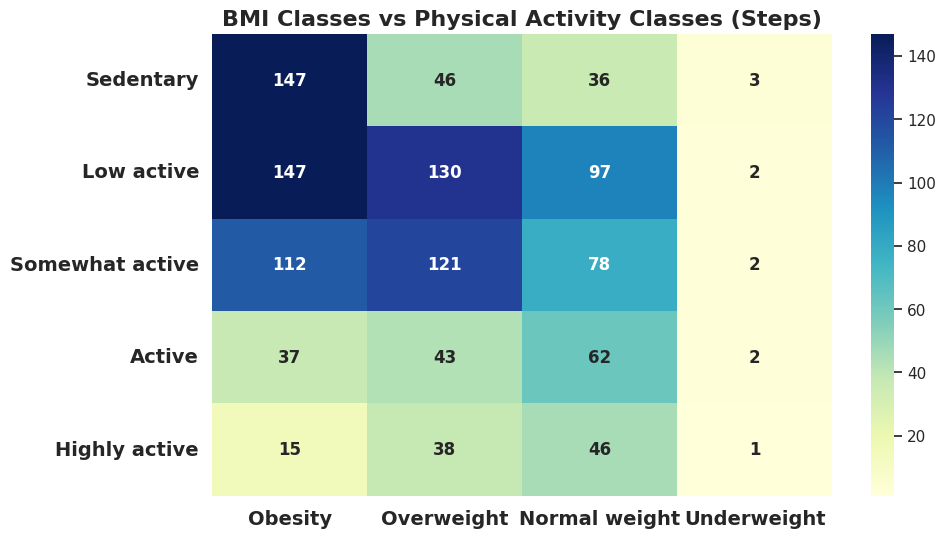

In [ ]:
#@title Create a crosstab for Diabetes vs IR-status
plt.figure(figsize=(6, 8))
crosstab = pd.crosstab(homa_ir_prediction_score_labels['Diabetes_Status'],
                       homa_ir_prediction_score_labels['homa_ir_status']
)

# Reorder the crosstab
desired_row_order = ['Diabetic', 'Prediabetic', 'Normoglycemic']
desired_column_order = ['IS', 'IMPAIRED-IS', 'IR']
crosstab = crosstab.reindex(index=desired_row_order, columns=desired_column_order)

# Plot a heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(crosstab, annot=True, fmt='d',cmap='YlGnBu', annot_kws={"size": 12, "weight": 'bold'})
plt.title('Insulin Resistance Status vs Diabetes Classes', fontsize=16, fontweight='bold')
plt.xlabel('')
plt.ylabel('')
plt.xticks(fontsize=14, fontweight='bold')
plt.yticks(fontsize=14, fontweight='bold',rotation=0)
plt.show()

## Plot IR numbers
plt.figure(figsize=(6, 8))
crosstab = pd.crosstab(homa_ir_prediction_score_labels['homa_ir_class_predicted'],
                       homa_ir_prediction_score_labels['homa_ir_class_true']
)

# Reorder the crosstab
desired_row_order = [0, 1]
desired_column_order = [0, 1]
crosstab = crosstab.reindex(index=desired_row_order, columns=desired_column_order)

# Plot a heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(crosstab, annot=True, fmt='d',cmap='YlGnBu', annot_kws={"size": 12, "weight": 'bold'})
plt.title('Insulin Resistance Status (True vs predicted)', fontsize=16, fontweight='bold')
plt.xlabel('homa_ir_class_true')
plt.ylabel('homa_ir_class_predicted')
plt.xticks(fontsize=14, fontweight='bold')
plt.yticks(fontsize=14, fontweight='bold',rotation=0)
plt.show()



# Create a crosstab for BMI vs IR-status
plt.figure(figsize=(6, 8))
crosstab = pd.crosstab(homa_ir_prediction_score_labels['bmi_class'],
                       homa_ir_prediction_score_labels['homa_ir_status']
)

# Reorder the crosstab
desired_row_order = ['Obesity', 'Overweight', 'Normal weight', 'Underweight']
desired_column_order = ['IS', 'IMPAIRED-IS', 'IR']
crosstab = crosstab.reindex(index=desired_row_order, columns=desired_column_order)

# Plot a heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(crosstab, annot=True, fmt='d',cmap='YlGnBu', annot_kws={"size": 12, "weight": 'bold'})
plt.title('Insulin Resistance Status vs BMI Classes', fontsize=16, fontweight='bold')
plt.xlabel('')
plt.ylabel('')
plt.xticks(fontsize=14, fontweight='bold')
plt.yticks(fontsize=14, fontweight='bold',rotation=0)
plt.show()



# Create a crosstab for Physical ctivity (steps) vs IR-status
plt.figure(figsize=(6, 8))
crosstab = pd.crosstab(homa_ir_prediction_score_labels['physical_activity_class_steps'],
                       homa_ir_prediction_score_labels['homa_ir_status']
)

# Reorder the crosstab
desired_row_order = ['Sedentary', 'Low active', 'Somewhat active', 'Active', 'Highly active']
desired_column_order = ['IS', 'IMPAIRED-IS', 'IR']
crosstab = crosstab.reindex(index=desired_row_order, columns=desired_column_order)

# Plot a heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(crosstab, annot=True, fmt='d',cmap='YlGnBu', annot_kws={"size": 12, "weight": 'bold'})
plt.title('Insulin Resistance Status vs Physical Activity Classes (Steps)', fontsize=16, fontweight='bold')
plt.xlabel('')
plt.ylabel('')
plt.xticks(fontsize=14, fontweight='bold')
plt.yticks(fontsize=14, fontweight='bold',rotation=0)
plt.show()


## Plot for Physical activity and Obesity
# Create a crosstab for Physical ctivity (AZM) vs IR-status
plt.figure(figsize=(6, 8))
crosstab = pd.crosstab(homa_ir_prediction_score_labels['physical_activity_class_steps'],
                       homa_ir_prediction_score_labels['bmi_class']
)

# Reorder the crosstab
desired_row_order = ['Sedentary', 'Low active', 'Somewhat active', 'Active', 'Highly active']
desired_column_order = ['Obesity', 'Overweight', 'Normal weight', 'Underweight']
crosstab = crosstab.reindex(index=desired_row_order, columns=desired_column_order)

# Plot a heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(crosstab, annot=True, fmt='d',cmap='YlGnBu', annot_kws={"size": 12, "weight": 'bold'})
plt.title('BMI Classes vs Physical Activity Classes (Steps)', fontsize=16, fontweight='bold')
plt.xlabel('')
plt.ylabel('')
plt.xticks(fontsize=14, fontweight='bold')
plt.yticks(fontsize=14, fontweight='bold',rotation=0)
plt.show()
